# Proyecto Integrador – Fase 3: Modelado Avanzado, Clustering, Optimización e Interpretabilidad

**Dataset:** *Hotel Booking Demand* (Kaggle, `jessemostipak/hotel-booking-demand`)

| | |
|---|---|
| **Asignatura** | Ciencia de Datos — Maestría en Inteligencia Artificial |
| **Institución** | Universidad de La Salle |
| **Integrantes** | Miguel Angel Ricardo · Jose Alexander Barahona Calderon |
| **Docente** | Fabián Camilo Castro Riveros |
| **Entregable** | Entregable 3 — Fase 3 (Actividades 5 y 6) |
| **Fecha de entrega** | 22 de noviembre de 2026 |
| **Ejecución documentada** | 23 de noviembre de 2026, Google Colab (GPU T4); las cifras del texto corresponden a estas salidas |

Este cuaderno parte de los **artefactos de la Fase 2** (`df_train_final.csv`, `df_val_final.csv`, `df_test_final.csv` y la definición de los preprocesadores) y los complementa con los tres bloques de modelado exigidos por la guía, más la red neuronal, la optimización con validación cruzada y la interpretabilidad. Es **ejecutable de principio a fin** en Google Colab o en local.

**Principios heredados de la Fase 2**

1. Todo lo que *aprende* de los datos (escaladores, encoders, hiperparámetros, umbrales, número de clústeres) se ajusta **solo con entrenamiento**; validación se usa para **seleccionar** y prueba **una sola vez**, al final.
2. La validación cruzada es **agrupada** por `grupo_dup`: las copias idénticas de una reserva nunca quedan a ambos lados de un pliegue.
3. Las variables con fuga (`reservation_status`, su fecha, `assigned_room_type`, `booking_changes`) siguen excluidas.

**Contenido**

| Bloque | Contenido |
|---|---|
| 0 | Entorno, librerías y semillas |
| 1 | Carga de artefactos de la Fase 2 y reconstrucción del preprocesador |
| 2 | Estrategia de evaluación y modelos base de referencia |
| 3 | Regresión del ADR: Ridge, Lasso, ElasticNet, Random Forest y XGBoost |
| 4 | Clasificación de la cancelación: Random Forest y XGBoost |
| 5 | Perceptrón Multicapa (MLP) en PyTorch |
| 6 | Clustering: K-Means (codo y silueta) y Jerárquico Aglomerativo |
| 7 | Interpretabilidad: SHAP, importancia por permutación y auditoría de `country` |
| 8 | Evaluación final en prueba y test de estrés temporal (2017) |
| 9 | Síntesis comparativa e impacto de negocio |
| 10 | Persistencia de modelos y reproducibilidad |

## 0. Preparación del entorno

### 0.1 Instalación de librerías
**Tiempo de ejecución:** ~20–25 min en una CPU de 8 núcleos (más en Colab gratuito, que tiene 2). Para una prueba rápida, poner `MODO_RAPIDO = True` en la celda 0.2 (las cifras del texto corresponden a `False`).

Además de las librerías de la Fase 2 se usan **XGBoost** (gradient boosting), **SHAP** (interpretabilidad) y **PyTorch** (MLP). En Colab, PyTorch y XGBoost ya vienen instalados; la celda solo asegura su presencia.

In [ ]:
!pip install -q xgboost shap

### 0.2 Importaciones, semillas y estilo gráfico
Se mantiene la semilla `SEED = 42` (NumPy, scikit-learn y PyTorch) y la paleta de las fases anteriores (**azul = no cancelada**, **naranja = cancelada**, **violeta = City Hotel**, **aqua = Resort Hotel**).

In [ ]:
import os
import re
import json
import urllib.request
import time
import random
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from IPython.display import display

import scipy
from scipy.stats import loguniform, randint, uniform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

import sklearn
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.model_selection import (GroupKFold, StratifiedGroupKFold, GroupShuffleSplit,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve, auc,
                             confusion_matrix, mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

import xgboost
from xgboost import XGBRegressor, XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

try:
    import shap
    SHAP_OK = True
except Exception as e:                      # el cuaderno sigue funcionando sin SHAP
    print("SHAP no disponible:", e)
    SHAP_OK = False

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# --- Semillas ---
SEED = 42
# MODO_RAPIDO = True reduce las búsquedas de hiperparámetros y las épocas del MLP para pruebas rápidas
# (~8 min). Las cifras citadas en el texto corresponden a MODO_RAPIDO = False (~20-25 min en 8 núcleos).
MODO_RAPIDO = False
N_ITER_RF, N_ITER_XGB = (4, 6) if MODO_RAPIDO else (12, 20)
EPOCAS_MLP = 15 if MODO_RAPIDO else 50
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
N_JOBS = -1

# --- Paleta (heredada de las Fases 1 y 2) ---
AZUL, NARANJA, AQUA, VIOLETA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#eda100"
ROJO, MARRON = "#c4314b", "#8c5a3c"
GRIS, GRIS_CLARO, GRIS_CUADRICULA = "#8a8985", "#c9c7c1", "#e6e5e1"
TINTA, TINTA_2 = "#1f1f1e", "#52514e"
PALETA_CLUSTER = [AZUL, NARANJA, AQUA, VIOLETA, AMARILLO, ROJO, MARRON, GRIS]

plt.rcParams.update({
    "figure.figsize": (11, 5), "figure.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRIS, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRIS_CUADRICULA, "grid.linewidth": 0.8,
    "axes.labelcolor": TINTA_2, "axes.labelsize": 10.5,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "font.size": 10.5, "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": cycler(color=[AZUL, NARANJA, AQUA, AMARILLO, VIOLETA]),
})
FUENTE = "Fuente: Hotel Booking Demand (Antonio, Almeida y Nunes, 2019) — Kaggle"

def titular(ax, titulo, subtitulo=None):
    ax.set_title(titulo, loc="left", fontsize=13, fontweight="bold", color=TINTA,
                 pad=24 if subtitulo else 10)
    if subtitulo:
        ax.text(0, 1.025, subtitulo, transform=ax.transAxes, fontsize=10,
                color=TINTA_2, va="bottom", ha="left")

def citar_fuente(fig, texto=FUENTE, y=-0.03):
    fig.text(0.01, y, texto, fontsize=8.5, color=GRIS, ha="left")

DIR_FIGURAS = "figures_fase3"
DIR_MODELOS = "modelos_fase3"
os.makedirs(DIR_FIGURAS, exist_ok=True)
os.makedirs(DIR_MODELOS, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(os.path.join(DIR_FIGURAS, f"{nombre}.png"), dpi=150, bbox_inches="tight")

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__, "| torch", torch.__version__, "| shap", shap.__version__ if SHAP_OK else "N/D")

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1
xgboost 3.4.1 | torch 2.14.1+cu130 | shap 0.54.1


## 1. Carga de artefactos de la Fase 2

### 1.1 Módulo de transformadores reutilizable
En la Fase 2 el `Winsorizer` y el constructor del preprocesador se definieron dentro del cuaderno. Para que los modelos guardados en esta fase puedan cargarse en el **dashboard de la Fase 4** (otro proceso de Python), ambos se escriben en un módulo `transformadores.py`. El código es **idéntico** al del Bloque 7–8 de la Fase 2.

In [ ]:
CODIGO_TRANSFORMADORES = '''
# Transformadores compartidos por las Fases 2, 3 y 4 (código idéntico al de la Fase 2).
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer


class Winsorizer(BaseEstimator, TransformerMixin):
    # Winsorización superior: recorta cada columna en su percentil q, aprendido SOLO en fit (train).
    def __init__(self, q=0.99):
        self.q = q

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.upper_bounds_ = X_df.quantile(self.q).to_dict()
        self.columnas_ = np.asarray(X_df.columns.astype(str), dtype=object)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for col, limite in self.upper_bounds_.items():
            X_df[col] = X_df[col].clip(upper=limite)
        return X_df.values

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return self.columnas_
        return np.asarray(input_features, dtype=object)


def crear_preprocesador(num_vars, cat_vars, es_regresion=False):
    # ColumnTransformer de la Fase 2: log1p+escala en lead_time, winsorización p99+escala en
    # adr/total_noches, StandardScaler en el resto y One-Hot con agrupación de categorías raras.
    lead_time_t = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                            ("scaler", StandardScaler())])
    otras_num = [v for v in num_vars if v not in ["lead_time", "total_noches", "adr"]]
    trs = [("lead_time_t", lead_time_t, ["lead_time"])]
    if es_regresion:
        trs.append(("noches_t", Pipeline([("wins", Winsorizer(q=0.99)), ("sc", StandardScaler())]),
                    ["total_noches"]))
    else:
        trs.append(("adr_noches_t", Pipeline([("wins", Winsorizer(q=0.99)), ("sc", StandardScaler())]),
                    ["adr", "total_noches"]))
    trs.append(("other_num", StandardScaler(), otras_num))
    cat_ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005,
                            sparse_output=False, drop="if_binary")
    ct = ColumnTransformer(transformers=[*trs, ("cat", cat_ohe, cat_vars)])
    ct.set_output(transform="pandas")
    return ct


def crear_preprocesador_clustering(vars_clust):
    # Preprocesador del clustering: log1p en lead_time, winsorización p99 en adr y total_noches
    # y estandarización final de todas las variables (ajustado solo en train).
    resto = [v for v in vars_clust if v not in ["lead_time", "adr", "total_noches"]]
    ct = ColumnTransformer([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), ["lead_time"]),
        ("wins", Winsorizer(q=0.99), ["adr", "total_noches"]),
        ("resto", "passthrough", resto),
    ], verbose_feature_names_out=False)
    return Pipeline([("ct", ct), ("sc", StandardScaler())])
'''
with open("transformadores.py", "w", encoding="utf-8") as f:
    f.write(CODIGO_TRANSFORMADORES)

import importlib, transformadores
importlib.reload(transformadores)
from transformadores import Winsorizer, crear_preprocesador, crear_preprocesador_clustering
print("Módulo transformadores.py escrito e importado.")

Módulo transformadores.py escrito e importado.


### 1.2 Carga de las particiones y reconstrucción de los conjuntos de variables
**Descarga automática:** si los CSV no están en la carpeta (por ejemplo, en una sesión nueva de Colab), la celda los descarga de los enlaces públicos definidos en `URLS_F2`; no es necesario subir archivos. En ejecución local se usan los archivos existentes.

Se cargan las tres particiones exportadas por la Fase 2. Dos detalles de tipos son importantes:

* `agent` es **nominal** (código de agencia), por lo que se lee como texto; si se leyera como número el modelo lo trataría como una cantidad.
* `grupo_dup` (llave de duplicados) se lee como texto porque solo se usa como identificador de grupo.

Las listas de variables se reconstruyen con las **mismas reglas de exclusión** del Bloque 5 de la Fase 2, respetando el orden de columnas del archivo, de modo que las matrices resultantes son idénticas a las de la Fase 2.

In [ ]:
# --- Descarga automática de los archivos de la Fase 2 ---
# Los CSV están publicados con enlace público ("Cualquier persona con el enlace" -> Lector), de modo que
# cualquiera puede ejecutar el cuaderno sin subir archivos. Se aceptan enlaces de Google Drive
# (https://drive.google.com/file/d/<ID>/view?usp=sharing) o URLs directas (p. ej., raw de GitHub).
URLS_F2 = {
    "df_train_final.csv": "https://drive.google.com/file/d/1b_nm19KSedCWJZk0jX56crRCG-hUIOKj/view?usp=sharing",
    "df_val_final.csv":   "https://drive.google.com/file/d/17GFvcv4jsLY-xd8CYT86GY7AmQ8VtuVu/view?usp=sharing",
    "df_test_final.csv":  "https://drive.google.com/file/d/1GQVQtsAX_rAgvlhW5WoZnAG0Vu91t5oX/view?usp=sharing",
}

def descargar(url, destino):
    m = re.search(r"/d/([\w-]+)|[?&]id=([\w-]+)", url)
    if "drive.google.com" in url and m:
        file_id = m.group(1) or m.group(2)
        try:
            import gdown                                   # preinstalado en Colab
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
            import gdown
        gdown.download(id=file_id, output=destino, quiet=True)
    else:
        urllib.request.urlretrieve(url, destino)

for archivo, url in URLS_F2.items():
    if os.path.exists(archivo):
        continue                                           # ya está en la carpeta (ejecución local)
    if url.startswith("PEGAR_"):
        raise FileNotFoundError(f"Falta {archivo} y no se ha configurado su enlace en URLS_F2.")
    print(f"Descargando {archivo} ...")
    descargar(url, archivo)
    with open(archivo, encoding="utf-8") as f:             # protección: Drive devuelve HTML si el enlace no es público
        assert f.readline().startswith("hotel,"), f"{archivo}: el enlace no es público o no es el CSV correcto"
print("Archivos de la Fase 2 disponibles:", [f for f in URLS_F2 if os.path.exists(f)])

DTYPES = {"agent": str, "grupo_dup": str}
df_train = pd.read_csv("df_train_final.csv", dtype=DTYPES)
df_val   = pd.read_csv("df_val_final.csv", dtype=DTYPES)
df_test  = pd.read_csv("df_test_final.csv", dtype=DTYPES)

# --- Reglas de exclusión del Bloque 5 (Fase 2) ---
FUGA_OPERATIVA = ["assigned_room_type", "booking_changes"]
CONTROL = ["id_original", "grupo_dup", "apto_regresion"]
exclusiones_clasif    = ["is_canceled", "reservation_status", "reservation_status_date"] + CONTROL + FUGA_OPERATIVA
exclusiones_regresion = ["adr", "is_canceled", "reservation_status", "reservation_status_date"] + CONTROL + FUGA_OPERATIVA

CAT_VARS = ["hotel", "arrival_date_month", "meal", "country", "market_segment",
            "distribution_channel", "reserved_room_type", "deposit_type", "agent", "customer_type"]

vars_clasif    = [c for c in df_train.columns if c not in exclusiones_clasif]
vars_regresion = [c for c in df_train.columns if c not in exclusiones_regresion]
num_clasif = [c for c in vars_clasif if c not in CAT_VARS]
cat_clasif = [c for c in vars_clasif if c in CAT_VARS]
num_regres = [c for c in vars_regresion if c not in CAT_VARS]
cat_regres = [c for c in vars_regresion if c in CAT_VARS]

assert (len(num_clasif), len(cat_clasif)) == (22, 10), "No coincide con la Fase 2 (22 + 10)"
assert (len(num_regres), len(cat_regres)) == (21, 10), "No coincide con la Fase 2 (21 + 10)"

# --- Verificación de la partición heredada ---
def grupos_compartidos(a, b):
    return len(set(a["grupo_dup"]) & set(b["grupo_dup"]))

for (n1, a), (n2, b) in [(("Train", df_train), ("Val", df_val)),
                         (("Train", df_train), ("Test", df_test)),
                         (("Val", df_val), ("Test", df_test))]:
    assert grupos_compartidos(a, b) == 0, f"Grupos compartidos entre {n1} y {n2}"

resumen = pd.DataFrame({
    "Conjunto": ["Train", "Val", "Test"],
    "Registros": [len(df_train), len(df_val), len(df_test)],
    "Tasa de cancelación": [d["is_canceled"].mean() for d in (df_train, df_val, df_test)],
    "Aptos regresión (adr > 0)": [int(d["apto_regresion"].sum()) for d in (df_train, df_val, df_test)],
})
display(resumen.style.format({"Registros": "{:,}", "Tasa de cancelación": "{:.2%}",
                              "Aptos regresión (adr > 0)": "{:,}"}))
print(f"Variables clasificación: {len(num_clasif)} numéricas + {len(cat_clasif)} categóricas")
print(f"Variables regresión:     {len(num_regres)} numéricas + {len(cat_regres)} categóricas")
print("Cero grupos de duplicados compartidos entre los tres conjuntos.")

Descargando df_train_final.csv ...
Descargando df_val_final.csv ...
Descargando df_test_final.csv ...
Archivos de la Fase 2 disponibles: ['df_train_final.csv', 'df_val_final.csv', 'df_test_final.csv']


,Conjunto,Registros,Tasa de cancelación,Aptos regresión (adr > 0)
0,Train,"83,610",37.39%,"82,384"
1,Val,"17,913",37.29%,"17,611"
2,Test,"17,670",35.33%,"17,400"


Variables clasificación: 22 numéricas + 10 categóricas
Variables regresión:     21 numéricas + 10 categóricas
Cero grupos de duplicados compartidos entre los tres conjuntos.


### 1.3 Preprocesadores (ajustados solo en entrenamiento)
Se intenta cargar `preproc_clasif.joblib` y `preproc_regres.joblib` de la Fase 2. Si el entorno tiene una versión de *scikit-learn* distinta a la de Colab (1.6.1), el objeto serializado no es compatible; en ese caso se **reconstruye** con el mismo código y se ajusta con `df_train`, lo que produce exactamente las mismas transformaciones porque el ajuste es determinístico. Si la carga funciona, se verifica que ambos coinciden.

In [ ]:
preproc_clasif = crear_preprocesador(num_clasif, cat_clasif, es_regresion=False).fit(df_train[vars_clasif])
preproc_regres = crear_preprocesador(num_regres, cat_regres, es_regresion=True).fit(df_train[vars_regresion])

# Comprobación contra los artefactos serializados de la Fase 2 (si el entorno los puede leer)
import __main__
__main__.Winsorizer = Winsorizer          # en la Fase 2 la clase vivía en __main__
for nombre, pre in [("preproc_clasif.joblib", preproc_clasif), ("preproc_regres.joblib", preproc_regres)]:
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pre_f2 = joblib.load(nombre)
            muestra = df_val[list(pre_f2.feature_names_in_)].head(500)
            iguales = np.allclose(pre_f2.transform(muestra).values, pre.transform(muestra).values)
        print(f"{nombre}: cargado; transformaciones idénticas a la reconstrucción = {iguales}")
    except FileNotFoundError:
        print(f"{nombre}: no está en la carpeta (no es necesario); se usa la reconstrucción ajustada en train.")
    except Exception as e:
        print(f"{nombre}: no compatible con scikit-learn {sklearn.__version__} "
              f"({type(e).__name__}); se usa la reconstrucción ajustada en train.")

# --- Matrices de clasificación ---
X_train_c = preproc_clasif.transform(df_train[vars_clasif])
X_val_c   = preproc_clasif.transform(df_val[vars_clasif])
X_test_c  = preproc_clasif.transform(df_test[vars_clasif])
y_train_c, y_val_c, y_test_c = df_train["is_canceled"], df_val["is_canceled"], df_test["is_canceled"]
g_train_c = df_train["grupo_dup"]

# --- Matrices de regresión: solo reservas con ingreso (apto_regresion == 1); adr NO se recorta ---
m_tr, m_va, m_te = (df_train["apto_regresion"] == 1), (df_val["apto_regresion"] == 1), (df_test["apto_regresion"] == 1)
X_train_r = preproc_regres.transform(df_train.loc[m_tr, vars_regresion])
X_val_r   = preproc_regres.transform(df_val.loc[m_va, vars_regresion])
X_test_r  = preproc_regres.transform(df_test.loc[m_te, vars_regresion])
y_train_r, y_val_r, y_test_r = df_train.loc[m_tr, "adr"], df_val.loc[m_va, "adr"], df_test.loc[m_te, "adr"]
g_train_r = df_train.loc[m_tr, "grupo_dup"]

FEATS_C = list(X_train_c.columns)
FEATS_R = list(X_train_r.columns)
print(f"Clasificación -> Train {X_train_c.shape} | Val {X_val_c.shape} | Test {X_test_c.shape}")
print(f"Regresión     -> Train {X_train_r.shape} | Val {X_val_r.shape} | Test {X_test_r.shape}")
assert X_train_c.shape[1] == 109 and X_train_r.shape[1] == 108, "Dimensiones distintas a la Fase 2"

preproc_clasif.joblib: no está en la carpeta (no es necesario); se usa la reconstrucción ajustada en train.
preproc_regres.joblib: no está en la carpeta (no es necesario); se usa la reconstrucción ajustada en train.
Clasificación -> Train (83610, 109) | Val (17913, 109) | Test (17670, 109)
Regresión     -> Train (82384, 108) | Val (17611, 108) | Test (17400, 108)


## 2. Estrategia de evaluación y modelos base de referencia

### 2.1 Protocolo
| Etapa | Datos | Uso |
|---|---|---|
| Búsqueda de hiperparámetros | **Train**, validación cruzada agrupada por `grupo_dup` (`GroupKFold` en regresión, `StratifiedGroupKFold` en clasificación) | Elegir hiperparámetros de cada algoritmo |
| Selección de modelo y umbral | **Validación** (15 %) | Comparar algoritmos, diagnosticar sobreajuste (train vs. val) y fijar el umbral de decisión |
| Evaluación final | **Prueba** (15 %), usada una sola vez | Estimación honesta del rendimiento |
| Test de estrés | Entrenar 2015–2016, evaluar 2017 | Robustez ante *concept drift* |

La validación cruzada **agrupada** es indispensable: con una validación cruzada aleatoria, las copias idénticas de una misma reserva quedarían en pliegues distintos y los hiperparámetros elegidos premiarían la memorización.

**Costo computacional.** Para Random Forest (el algoritmo más costoso) la búsqueda se realiza sobre una **submuestra agrupada del 30 %** de entrenamiento y el modelo final se reentrena con todo el conjunto de entrenamiento. XGBoost y los modelos lineales se ajustan sobre el entrenamiento completo.

### 2.2 Funciones de evaluación y modelos base
Se recalculan los *baselines* de la Fase 2 (mismas definiciones) para tenerlos en la misma tabla que los modelos nuevos.

In [ ]:
def metricas_clasif(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    p, r, _ = precision_recall_curve(y, prob)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, prob), "PR-AUC": auc(r, p)}

def metricas_regres(y, pred):
    return {"MAE (€)": mean_absolute_error(y, pred),
            "RMSE (€)": np.sqrt(mean_squared_error(y, pred)),
            "R2": r2_score(y, pred)}

def umbral_optimo_f1(y, prob):
    """Umbral que maximiza F1 (se calcula en VALIDACIÓN, nunca en prueba)."""
    p, r, t = precision_recall_curve(y, prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(t[i]), float(f1[i])

# --- Baselines de clasificación (Fase 2) ---
t0 = time.time()
base_lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED).fit(X_train_c, y_train_c)
base_dummy_c = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train_c, y_train_c)
res_c_val = {
    "Dummy (Stratified)": metricas_clasif(y_val_c, base_dummy_c.predict_proba(X_val_c)[:, 1]),
    "LogReg balanced (baseline)": metricas_clasif(y_val_c, base_lr.predict_proba(X_val_c)[:, 1]),
}
res_c_train = {"LogReg balanced (baseline)": metricas_clasif(y_train_c, base_lr.predict_proba(X_train_c)[:, 1])}

# --- Baselines de regresión (Fase 2) ---
VAR_SIMPLE = "total_huespedes"
base_dummy_r = DummyRegressor(strategy="mean").fit(X_train_r, y_train_r)
base_simple = LinearRegression().fit(df_train.loc[m_tr, [VAR_SIMPLE]], y_train_r)
base_ols = LinearRegression().fit(X_train_r, y_train_r)
res_r_val = {
    "Dummy (media)": metricas_regres(y_val_r, base_dummy_r.predict(X_val_r)),
    "Lineal simple (baseline)": metricas_regres(y_val_r, base_simple.predict(df_val.loc[m_va, [VAR_SIMPLE]])),
    "OLS múltiple (referencia)": metricas_regres(y_val_r, base_ols.predict(X_val_r)),
}
res_r_train = {"Lineal simple (baseline)": metricas_regres(y_train_r, base_simple.predict(df_train.loc[m_tr, [VAR_SIMPLE]])),
               "OLS múltiple (referencia)": metricas_regres(y_train_r, base_ols.predict(X_train_r))}

display(pd.DataFrame(res_c_val).T.style.format("{:.3f}").set_caption("Baselines de clasificación (validación)"))
display(pd.DataFrame(res_r_val).T.style.format("{:.3f}").set_caption("Baselines de regresión (validación)"))
print(f"Tiempo: {time.time() - t0:.1f} s")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Dummy (Stratified),0.528,0.366,0.361,0.364,0.495,0.483
LogReg balanced (baseline),0.821,0.739,0.805,0.771,0.902,0.858


,MAE (€),RMSE (€),R2
Dummy (media),35.735,47.125,-0.000
Lineal simple (baseline),32.178,42.091,0.202
OLS múltiple (referencia),20.511,28.572,0.632


Tiempo: 11.5 s


Los valores coinciden con los de la Fase 2 (ROC-AUC = 0.902 y F1 = 0.771 para la regresión logística ponderada; R² = 0.202 para la regresión lineal simple y 0.632 para OLS múltiple). Estos son los **umbrales mínimos** que los modelos avanzados deben superar.

## 3. Regresión: predicción del ADR (tarifa diaria promedio)

**Pregunta de negocio:** ¿qué tarifa diaria se puede esperar de una reserva según sus características (hotel, temporada, tipo de habitación, segmento, composición del grupo)? Un buen estimador sirve para detectar tarifas fuera de rango y para proyectar ingresos.

Se entrenan dos familias exigidas por la guía:

1. **Lineales regularizadas (Ridge, Lasso, ElasticNet).** Con 108 columnas, muchas de ellas *dummies* correlacionadas, la regularización controla la varianza de los coeficientes. Ridge (L2) encoge todos los coeficientes; Lasso (L1) anula los irrelevantes (selección de variables); ElasticNet combina ambos. El parámetro `alpha` se elige con **GridSearchCV + GroupKFold (5 pliegues)**.
2. **Ensambles de árboles (Random Forest y XGBoost).** El precio depende de **interacciones** (p. ej., temporada × hotel × tipo de habitación) que un modelo lineal no captura sin ingeniería manual. Se optimizan con **RandomizedSearchCV**.

### 3.1 Modelos lineales regularizados

In [ ]:
cv_r = GroupKFold(n_splits=5)
lineales = {
    "Ridge":      (Ridge(random_state=SEED), {"alpha": np.logspace(-2, 3, 11)}),
    # precompute=True usa la matriz de Gram (X'X, 108x108): con n >> p acelera el descenso por
    # coordenadas ~40 veces sin cambiar la solución
    "Lasso":      (Lasso(max_iter=10_000, precompute=True, random_state=SEED), {"alpha": np.logspace(-3, 0.5, 8)}),
    "ElasticNet": (ElasticNet(max_iter=10_000, precompute=True, random_state=SEED),
                   {"alpha": np.logspace(-3, 0, 5), "l1_ratio": [0.2, 0.5, 0.8]}),
}
busquedas_r, modelos_r, tiempos_r = {}, {}, {}
for nombre, (est, grid) in lineales.items():
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=cv_r, scoring="neg_root_mean_squared_error", n_jobs=N_JOBS)
    gs.fit(X_train_r, y_train_r, groups=g_train_r)
    busquedas_r[nombre], modelos_r[nombre], tiempos_r[nombre] = gs, gs.best_estimator_, time.time() - t0
    print(f"{nombre:<11} mejores parámetros: {gs.best_params_} | RMSE CV = {-gs.best_score_:.2f} € "
          f"| {tiempos_r[nombre]:.0f} s")

coef_lasso = pd.Series(modelos_r["Lasso"].coef_, index=FEATS_R)
coef_enet = pd.Series(modelos_r["ElasticNet"].coef_, index=FEATS_R)
print(f"\nLasso anula {int((coef_lasso == 0).sum())} de {len(coef_lasso)} coeficientes; "
      f"ElasticNet anula {int((coef_enet == 0).sum())}.")

Ridge       mejores parámetros: {'alpha': np.float64(0.01)} | RMSE CV = 28.61 € | 23 s
Lasso       mejores parámetros: {'alpha': np.float64(0.001)} | RMSE CV = 28.62 € | 13 s
ElasticNet  mejores parámetros: {'alpha': np.float64(0.001), 'l1_ratio': 0.8} | RMSE CV = 28.63 € | 13 s

Lasso anula 7 de 108 coeficientes; ElasticNet anula 3.


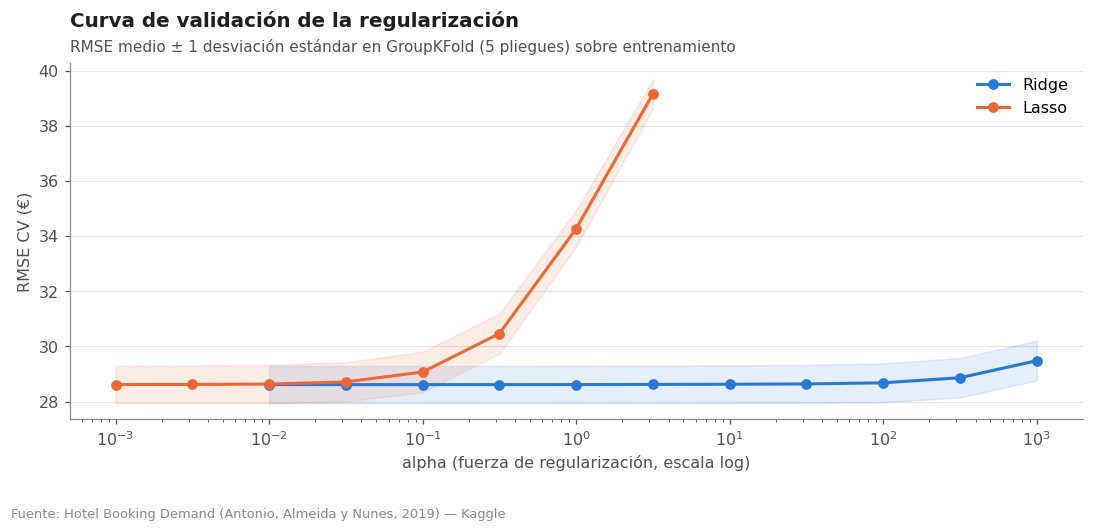

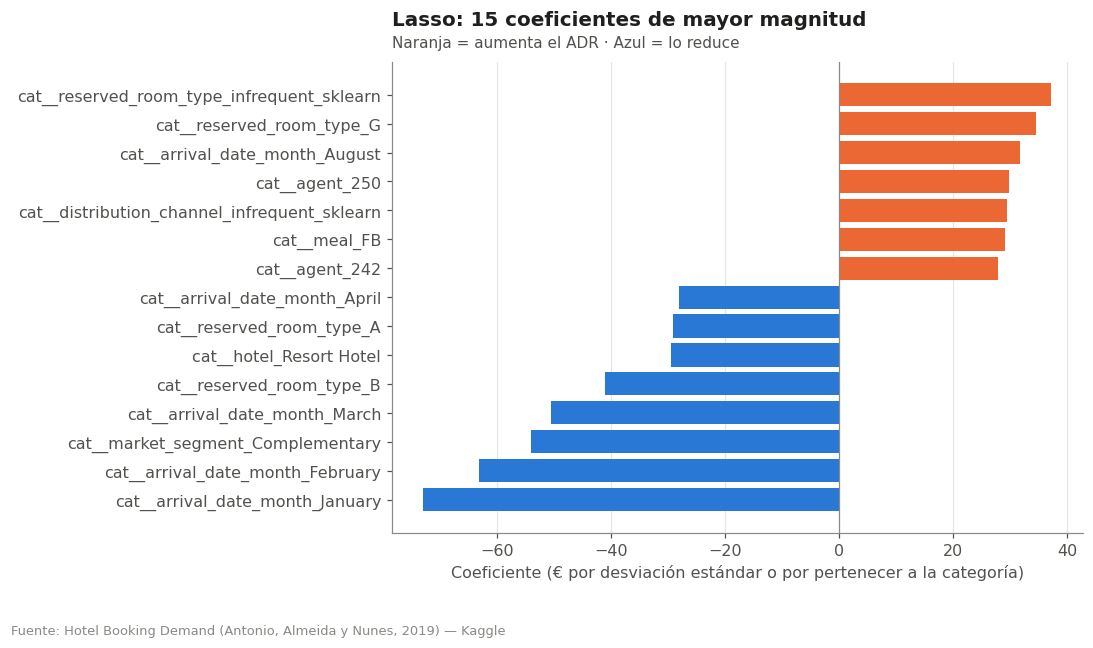

In [ ]:
# Curvas de validación de alpha (RMSE de validación cruzada agrupada)
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre, color in [("Ridge", AZUL), ("Lasso", NARANJA)]:
    cvres = pd.DataFrame(busquedas_r[nombre].cv_results_)
    ax.plot(cvres["param_alpha"].astype(float), -cvres["mean_test_score"], marker="o", color=color, label=nombre)
    ax.fill_between(cvres["param_alpha"].astype(float),
                    -cvres["mean_test_score"] - cvres["std_test_score"],
                    -cvres["mean_test_score"] + cvres["std_test_score"], color=color, alpha=0.12)
ax.set_xscale("log"); ax.set_xlabel("alpha (fuerza de regularización, escala log)"); ax.set_ylabel("RMSE CV (€)")
ax.legend()
titular(ax, "Curva de validación de la regularización",
        "RMSE medio ± 1 desviación estándar en GroupKFold (5 pliegues) sobre entrenamiento")
citar_fuente(fig, y=-0.06); plt.tight_layout(); guardar(fig, "3_1_curva_alpha_lineales"); plt.show()

# Coeficientes más influyentes del Lasso (variables estandarizadas: comparables entre sí)
top = coef_lasso[coef_lasso != 0].sort_values(key=np.abs, ascending=False).head(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top.index, top.values, color=[NARANJA if v > 0 else AZUL for v in top.values])
ax.axvline(0, color=GRIS, lw=0.8); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente (€ por desviación estándar o por pertenecer a la categoría)")
titular(ax, "Lasso: 15 coeficientes de mayor magnitud", "Naranja = aumenta el ADR · Azul = lo reduce")
citar_fuente(fig, y=-0.06); plt.tight_layout(); guardar(fig, "3_1_coeficientes_lasso"); plt.show()

### 3.2 Ensambles de árboles: Random Forest y XGBoost

In [ ]:
# --- Random Forest: búsqueda en submuestra agrupada del 30 % de train, reentrenamiento en train completo ---
gss = GroupShuffleSplit(n_splits=1, train_size=0.30, random_state=SEED)
idx_sub_r, _ = next(gss.split(X_train_r, y_train_r, groups=g_train_r))
print(f"Submuestra para la búsqueda de RF: {len(idx_sub_r):,} registros")

t0 = time.time()
rs_rf_r = RandomizedSearchCV(
    RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=1),
    param_distributions={"max_depth": [None, 15, 25, 35], "min_samples_leaf": [1, 2, 4, 8],
                         "max_features": [0.2, 0.33, 0.5, "sqrt"]},
    n_iter=N_ITER_RF, cv=GroupKFold(n_splits=3), scoring="neg_root_mean_squared_error",
    random_state=SEED, n_jobs=N_JOBS)
rs_rf_r.fit(X_train_r.iloc[idx_sub_r], y_train_r.iloc[idx_sub_r], groups=g_train_r.iloc[idx_sub_r])
print(f"RF mejores parámetros: {rs_rf_r.best_params_} | RMSE CV (submuestra) = {-rs_rf_r.best_score_:.2f} €")

rf_r = RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=N_JOBS, **rs_rf_r.best_params_)
rf_r.fit(X_train_r, y_train_r)
modelos_r["Random Forest"], tiempos_r["Random Forest"] = rf_r, time.time() - t0
print(f"Random Forest reentrenado en train completo | {tiempos_r['Random Forest']:.0f} s")

# --- XGBoost: búsqueda aleatoria sobre train completo con GroupKFold (3) ---
t0 = time.time()
rs_xgb_r = RandomizedSearchCV(
    XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=1),
    param_distributions={"n_estimators": randint(300, 1000), "learning_rate": loguniform(0.02, 0.2),
                         "max_depth": randint(4, 11), "min_child_weight": randint(1, 10),
                         "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.4, 0.6),
                         "reg_lambda": loguniform(0.1, 10)},
    n_iter=N_ITER_XGB, cv=GroupKFold(n_splits=3), scoring="neg_root_mean_squared_error",
    random_state=SEED, n_jobs=N_JOBS)
rs_xgb_r.fit(X_train_r, y_train_r, groups=g_train_r)
modelos_r["XGBoost"], tiempos_r["XGBoost"] = rs_xgb_r.best_estimator_, time.time() - t0
print(f"XGB mejores parámetros: { {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rs_xgb_r.best_params_.items()} }")
print(f"XGB RMSE CV = {-rs_xgb_r.best_score_:.2f} € | {tiempos_r['XGBoost']:.0f} s")

Submuestra para la búsqueda de RF: 24,542 registros
RF mejores parámetros: {'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 35} | RMSE CV (submuestra) = 18.83 €
Random Forest reentrenado en train completo | 412 s
XGB mejores parámetros: {'colsample_bytree': np.float64(0.6963), 'learning_rate': np.float64(0.0666), 'max_depth': 10, 'min_child_weight': 3, 'n_estimators': 874, 'reg_lambda': np.float64(6.1877), 'subsample': np.float64(0.7901)}
XGB RMSE CV = 14.40 € | 589 s


### 3.3 Comparación en validación y diagnóstico de sobreajuste
Se reportan las métricas en **entrenamiento** y **validación**. Una brecha grande (R² train ≫ R² val) indica sobreajuste.

In [ ]:
pred_val_r = {}
for nombre, m in modelos_r.items():
    pred_val_r[nombre] = m.predict(X_val_r)
    res_r_val[nombre] = metricas_regres(y_val_r, pred_val_r[nombre])
    res_r_train[nombre] = metricas_regres(y_train_r, m.predict(X_train_r))

orden_r = ["Dummy (media)", "Lineal simple (baseline)", "OLS múltiple (referencia)",
           "Ridge", "Lasso", "ElasticNet", "Random Forest", "XGBoost"]
tabla_r = pd.DataFrame(res_r_val).T.loc[orden_r]
tabla_r["R2 train"] = [res_r_train.get(n, {}).get("R2", np.nan) for n in orden_r]
tabla_r["Brecha R2 (train − val)"] = tabla_r["R2 train"] - tabla_r["R2"]
tabla_r["Tiempo (s)"] = [tiempos_r.get(n, np.nan) for n in orden_r]
display(tabla_r.style.format("{:.3f}").format({"Tiempo (s)": "{:.0f}"}, na_rep="—")
        .highlight_min(subset=["MAE (€)", "RMSE (€)"], color="#d9ecff")
        .highlight_max(subset=["R2"], color="#d9ecff"))

MEJOR_REG = tabla_r.loc[["Ridge", "Lasso", "ElasticNet", "Random Forest", "XGBoost"], "RMSE (€)"].idxmin()
print(f"Mejor regresor en validación (menor RMSE): {MEJOR_REG}")

,MAE (€),RMSE (€),R2,R2 train,Brecha R2 (train − val),Tiempo (s)
Dummy (media),35.735016,47.125385,-0.000491,—,—,—
Lineal simple (baseline),32.178218,42.091233,0.201846,0.189059,-0.012787,—
OLS múltiple (referencia),20.511267,28.571916,0.632225,0.627042,-0.005183,—
Ridge,20.511237,28.571871,0.632226,0.627042,-0.005185,23
Lasso,20.508341,28.564436,0.632418,0.626939,-0.005479,13
ElasticNet,20.521164,28.571633,0.632232,0.626545,-0.005688,13
Random Forest,8.078201,14.465724,0.905728,0.987865,0.082137,412
XGBoost,7.835506,13.298724,0.920325,0.983571,0.063246,589


Mejor regresor en validación (menor RMSE): XGBoost


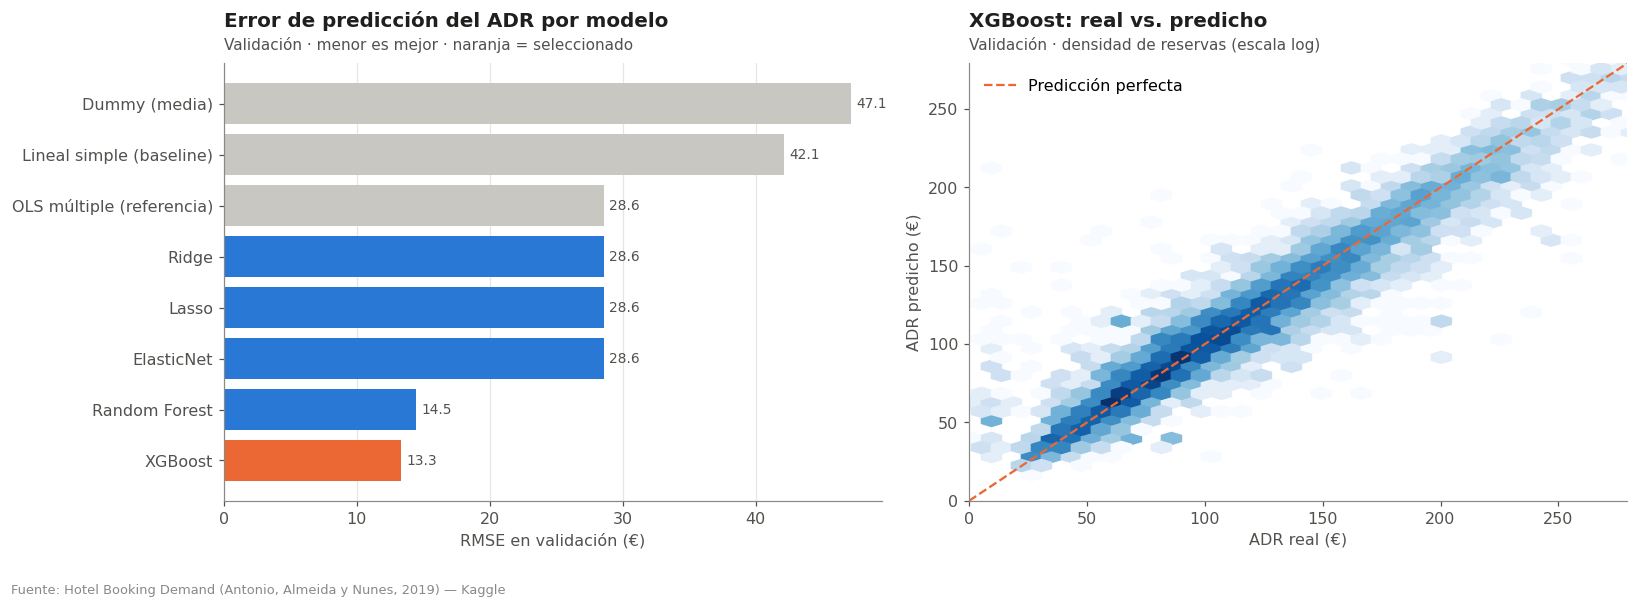

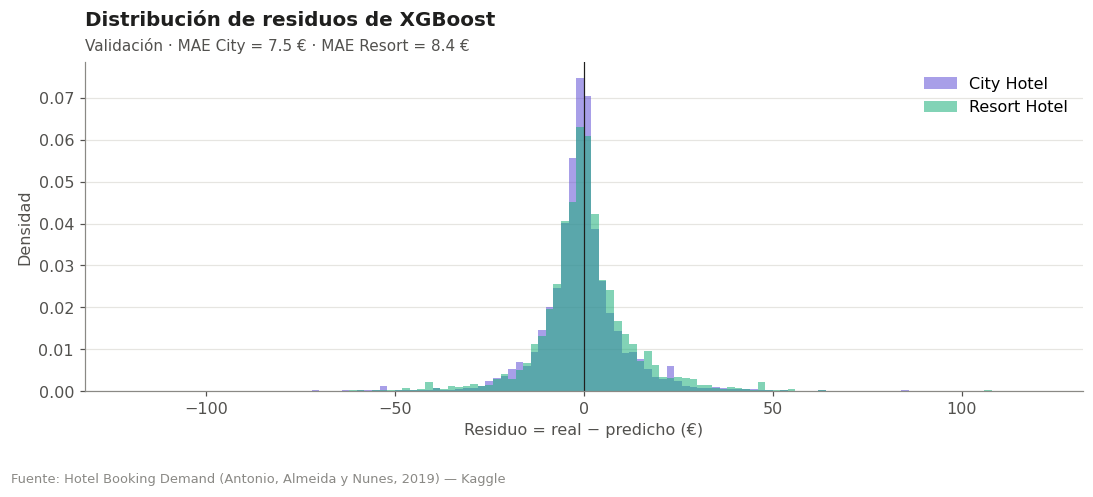

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
# (a) RMSE por modelo
t = tabla_r["RMSE (€)"].iloc[::-1]
colores = [NARANJA if n == MEJOR_REG else (AZUL if n in modelos_r else GRIS_CLARO) for n in t.index]
axes[0].barh(t.index, t.values, color=colores)
for i, v in enumerate(t.values):
    axes[0].text(v + 0.4, i, f"{v:.1f}", va="center", fontsize=9, color=TINTA_2)
axes[0].grid(axis="x"); axes[0].grid(axis="y", visible=False); axes[0].set_xlabel("RMSE en validación (€)")
titular(axes[0], "Error de predicción del ADR por modelo", "Validación · menor es mejor · naranja = seleccionado")

# (b) Real vs. predicho del mejor modelo
axes[1].hexbin(y_val_r, pred_val_r[MEJOR_REG], gridsize=60, cmap="Blues", mincnt=1, bins="log")
lim = [0, np.percentile(y_val_r, 99.5)]
axes[1].plot(lim, lim, color=NARANJA, lw=1.5, ls="--", label="Predicción perfecta")
axes[1].set_xlim(lim); axes[1].set_ylim(lim); axes[1].grid(False)
axes[1].set_xlabel("ADR real (€)"); axes[1].set_ylabel("ADR predicho (€)"); axes[1].legend(loc="upper left")
titular(axes[1], f"{MEJOR_REG}: real vs. predicho", "Validación · densidad de reservas (escala log)")
citar_fuente(fig, y=-0.05); plt.tight_layout(); guardar(fig, "3_3_comparacion_regresion"); plt.show()

# Residuos del mejor modelo por hotel
res = y_val_r - pred_val_r[MEJOR_REG]
fig, ax = plt.subplots(figsize=(10, 4.2))
hot_val = df_val.loc[m_va, "hotel"]
for h, c in [("City Hotel", VIOLETA), ("Resort Hotel", AQUA)]:
    ax.hist(res[hot_val == h], bins=120, range=(-120, 120), alpha=0.55, color=c, label=h, density=True)
ax.axvline(0, color=TINTA, lw=0.8); ax.set_xlabel("Residuo = real − predicho (€)"); ax.set_ylabel("Densidad")
ax.legend()
titular(ax, f"Distribución de residuos de {MEJOR_REG}",
        f"Validación · MAE City = {res[hot_val == 'City Hotel'].abs().mean():.1f} € · "
        f"MAE Resort = {res[hot_val == 'Resort Hotel'].abs().mean():.1f} €")
citar_fuente(fig, y=-0.06); plt.tight_layout(); guardar(fig, "3_3_residuos_regresion"); plt.show()

### 3.4 Interpretación de la regresión
**Resultados en validación (reservas con ADR > 0)**

| Modelo | MAE (€) | RMSE (€) | R² val | R² train | Brecha |
|---|---|---|---|---|---|
| Lineal simple (baseline Fase 2) | 32.18 | 42.09 | 0.202 | 0.189 | −0.013 |
| Ridge (α = 0.01) | 20.51 | 28.57 | 0.632 | 0.627 | −0.005 |
| Lasso (α = 0.001) | 20.51 | 28.56 | 0.632 | 0.627 | −0.005 |
| ElasticNet (α = 0.001, L1 = 0.8) | 20.52 | 28.57 | 0.632 | 0.627 | −0.006 |
| Random Forest | 8.08 | 14.47 | 0.906 | 0.988 | 0.082 |
| **XGBoost** | **7.84** | **13.30** | **0.920** | 0.984 | 0.063 |

* **Modelos lineales regularizados.** Los tres convergen al mismo resultado que OLS (R² ≈ 0.632) y la búsqueda elige la regularización **más débil** de la rejilla (Lasso solo anula 7 de 108 coeficientes). La explicación es estructural: con ~82,000 observaciones y 108 columnas (≈ 760 observaciones por parámetro), la varianza de los coeficientes ya es baja y no hay sobreajuste que corregir (la brecha train–val es incluso negativa). El límite de estos modelos es de **sesgo**, no de varianza: suponen efectos aditivos, mientras que el precio surge de interacciones (temporada × hotel × tipo de habitación). Su valor está en la **interpretabilidad**: los coeficientes del Lasso cuantifican en euros el efecto de cada categoría.
* **Ensambles de árboles.** Reducen el RMSE a la mitad (28.6 → 13.3 €) y elevan el R² de 0.63 a **0.92**, porque capturan esas interacciones automáticamente. XGBoost supera a Random Forest en RMSE (13.3 frente a 14.5 €) y, por menor margen, en MAE (7.84 frente a 8.08 €): el *boosting* corrige mejor los errores grandes (tarifas altas).
* **Sobreajuste.** Random Forest muestra la mayor brecha (R² train 0.988 frente a 0.906 en val), típica de árboles profundos (`max_depth = 35`, `min_samples_leaf = 1`); XGBoost, con regularización L2 (`reg_lambda ≈ 6.2`) y submuestreo, reduce la brecha a 0.063. Ambas brechas son moderadas y el rendimiento en validación es muy superior al de los lineales, así que el sobreajuste no compromete la generalización (se confirma en prueba, Bloque 8).
* **Residuos.** Se concentran alrededor de cero y son algo más dispersos en el Resort Hotel, cuya tarifa depende más de la temporada.

**Modelo seleccionado: XGBoost** (MAE ≈ 8 € por noche frente a 32 € del baseline: una reducción del **76 %** del error).

## 4. Clasificación: predicción de la cancelación

**Pregunta de negocio:** ¿qué reservas tienen alta probabilidad de cancelarse? Con esa probabilidad el hotel puede aplicar *overbooking* controlado, pedir depósitos o contactar al cliente.

Se comparan dos algoritmos de la lista de la guía, elegidos por ser complementarios:

* **Random Forest (bagging):** promedia muchos árboles profundos entrenados en muestras *bootstrap*; reduce varianza y es robusto a outliers y a escalas.
* **XGBoost (boosting):** construye árboles poco profundos de forma secuencial, cada uno corrigiendo los errores del anterior; suele lograr el mejor rendimiento en datos tabulares y tiene regularización explícita.

El desbalance (37 % / 63 %) se trata, igual que en la Fase 2, con **ponderación de clases**: `class_weight` en Random Forest y `scale_pos_weight = n_neg / n_pos` en XGBoost. La métrica de optimización es **ROC-AUC** (independiente del umbral) y el umbral de decisión se ajusta después en validación para maximizar F1.

### 4.1 Búsqueda de hiperparámetros con validación cruzada agrupada y estratificada

In [ ]:
cv_c = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
SPW = float((y_train_c == 0).sum() / (y_train_c == 1).sum())
print(f"scale_pos_weight = n_neg / n_pos = {SPW:.3f}")
modelos_c, tiempos_c, busquedas_c = {}, {}, {}

# --- Random Forest: búsqueda en submuestra agrupada del 30 % usando Pipeline ---
gss = GroupShuffleSplit(n_splits=1, train_size=0.30, random_state=SEED)
idx_sub_c, _ = next(gss.split(df_train[vars_clasif], y_train_c, groups=g_train_c))
t0 = time.time()

pipe_rf_c = Pipeline([
    ("pre", crear_preprocesador(num_clasif, cat_clasif, es_regresion=False)),
    ("model", RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=1))
])

param_dist_rf = {
    "model__max_depth": [None, 15, 25, 35],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", 0.15, 0.3],
    "model__class_weight": ["balanced", "balanced_subsample"]
}

rs_rf_c = RandomizedSearchCV(
    pipe_rf_c, param_distributions=param_dist_rf,
    n_iter=N_ITER_RF, cv=cv_c, scoring="roc_auc", random_state=SEED, n_jobs=N_JOBS
)
rs_rf_c.fit(df_train[vars_clasif].iloc[idx_sub_c], y_train_c.iloc[idx_sub_c], groups=g_train_c.iloc[idx_sub_c])
busquedas_c["Random Forest"] = rs_rf_c

# Re-entrenamiento final en el train completo utilizando los mejores parámetros
mejores_params_rf = {k.replace("model__", ""): v for k, v in rs_rf_c.best_params_.items()}
rf_c = RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=N_JOBS, **mejores_params_rf)
rf_c.fit(X_train_c, y_train_c)
modelos_c["Random Forest"] = rf_c
tiempos_c["Random Forest"] = time.time() - t0
print(f"RF mejores parámetros: {mejores_params_rf} | ROC-AUC CV (submuestra) = {rs_rf_c.best_score_:.4f} | {tiempos_c['Random Forest']:.0f} s")

# --- XGBoost: búsqueda en train completo usando Pipeline ---
t0 = time.time()
pipe_xgb_c = Pipeline([
    ("pre", crear_preprocesador(num_clasif, cat_clasif, es_regresion=False)),
    ("model", XGBClassifier(tree_method="hist", scale_pos_weight=SPW, eval_metric="logloss", random_state=SEED, n_jobs=1))
])

param_dist_xgb = {
    "model__n_estimators": randint(300, 1000),
    "model__learning_rate": loguniform(0.02, 0.2),
    "model__max_depth": randint(4, 11),
    "model__min_child_weight": randint(1, 10),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.4, 0.6),
    "model__gamma": uniform(0, 2),
    "model__reg_lambda": loguniform(0.1, 10)
}

rs_xgb_c = RandomizedSearchCV(
    pipe_xgb_c, param_distributions=param_dist_xgb,
    n_iter=N_ITER_XGB, cv=cv_c, scoring="roc_auc", random_state=SEED, n_jobs=N_JOBS
)
rs_xgb_c.fit(df_train[vars_clasif], y_train_c, groups=g_train_c)
busquedas_c["XGBoost"] = rs_xgb_c

# Extraer y entrenar el mejor estimador (Pipeline completo ya optimizado)
# El estimador final del Pipeline está en 'model' y sus hiperparámetros ya están ajustados
modelos_c["XGBoost"] = rs_xgb_c.best_estimator_.named_steps["model"]
tiempos_c["XGBoost"] = time.time() - t0

mejores_params_xgb = {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in rs_xgb_c.best_params_.items()}
print(f"XGB mejores parámetros: {mejores_params_xgb}")
print(f"XGB ROC-AUC CV = {rs_xgb_c.best_score_:.4f} | {tiempos_c['XGBoost']:.0f} s")

scale_pos_weight = n_neg / n_pos = 1.674
RF mejores parámetros: {'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 15, 'class_weight': 'balanced_subsample'} | ROC-AUC CV (submuestra) = 0.9315 | 288 s
XGB mejores parámetros: {'colsample_bytree': np.float64(0.7671), 'gamma': np.float64(0.279), 'learning_rate': np.float64(0.0392), 'max_depth': 10, 'min_child_weight': 3, 'n_estimators': 866, 'reg_lambda': np.float64(9.2568), 'subsample': np.float64(0.7867)}
XGB ROC-AUC CV = 0.9430 | 669 s


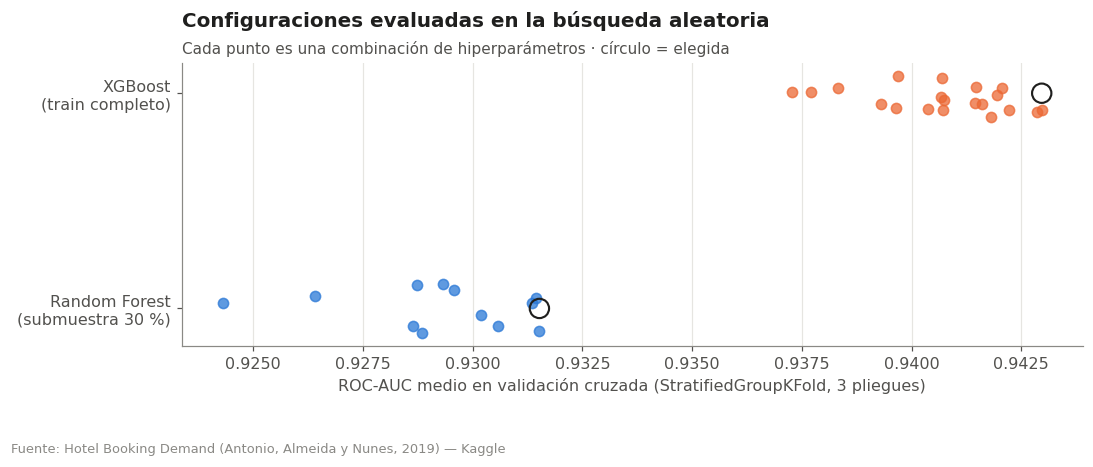

In [ ]:
# Estabilidad de la búsqueda: distribución del ROC-AUC CV de las configuraciones probadas
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (nombre, color) in enumerate([("Random Forest", AZUL), ("XGBoost", NARANJA)]):
    cvres = pd.DataFrame(busquedas_c[nombre].cv_results_)
    ax.scatter(cvres["mean_test_score"], np.full(len(cvres), i) + np.random.uniform(-0.12, 0.12, len(cvres)),
               s=45, color=color, alpha=0.75, label=nombre)
    ax.scatter(cvres["mean_test_score"].max(), i, s=160, facecolors="none", edgecolors=TINTA, lw=1.4)
ax.set_yticks([0, 1]); ax.set_yticklabels(["Random Forest\n(submuestra 30 %)", "XGBoost\n(train completo)"])
ax.set_xlabel("ROC-AUC medio en validación cruzada (StratifiedGroupKFold, 3 pliegues)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
titular(ax, "Configuraciones evaluadas en la búsqueda aleatoria", "Cada punto es una combinación de hiperparámetros · círculo = elegida")
citar_fuente(fig, y=-0.1); plt.tight_layout(); guardar(fig, "4_1_busqueda_hiperparametros"); plt.show()

### 4.2 Comparación en validación, umbral de decisión y sobreajuste
El umbral por defecto (0.5) no es necesariamente el mejor para el negocio. Se calcula en **validación** el umbral que maximiza F1 para cada modelo; ese umbral se aplicará sin cambios al conjunto de prueba (Bloque 8).

In [ ]:
prob_val_c = {"LogReg balanced (baseline)": base_lr.predict_proba(X_val_c)[:, 1]}
for nombre, m in modelos_c.items():
    prob_val_c[nombre] = m.predict_proba(X_val_c)[:, 1]
    res_c_val[nombre] = metricas_clasif(y_val_c, prob_val_c[nombre])
    res_c_train[nombre] = metricas_clasif(y_train_c, m.predict_proba(X_train_c)[:, 1])

UMBRALES = {n: umbral_optimo_f1(y_val_c, p)[0] for n, p in prob_val_c.items()}
filas = []
for n in ["Dummy (Stratified)", "LogReg balanced (baseline)", "Random Forest", "XGBoost"]:
    fila = {"Modelo": n, **res_c_val[n]}
    if n in UMBRALES:
        fila["Umbral F1"] = UMBRALES[n]
        fila["F1 @ umbral"] = f1_score(y_val_c, (prob_val_c[n] >= UMBRALES[n]).astype(int))
    fila["ROC-AUC train"] = res_c_train.get(n, {}).get("ROC-AUC", np.nan)
    filas.append(fila)
tabla_c = pd.DataFrame(filas).set_index("Modelo")
tabla_c["Brecha AUC (train − val)"] = tabla_c["ROC-AUC train"] - tabla_c["ROC-AUC"]
display(tabla_c.style.format("{:.3f}", na_rep="—").highlight_max(subset=["ROC-AUC", "F1", "PR-AUC"], color="#d9ecff"))

MEJOR_CLF = tabla_c.loc[["Random Forest", "XGBoost"], "ROC-AUC"].idxmax()
print(f"Mejor clasificador en validación (ROC-AUC): {MEJOR_CLF} | umbral elegido = {UMBRALES[MEJOR_CLF]:.3f}")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,ROC-AUC train,Umbral F1,F1 @ umbral,Brecha AUC (train − val)
Modelo,,,,,,,,,,
Dummy (Stratified),0.528,0.366,0.361,0.364,0.495,0.483,—,—,—,—
LogReg balanced (baseline),0.821,0.739,0.805,0.771,0.902,0.858,0.912,0.491,0.772,0.010
Random Forest,0.858,0.797,0.830,0.813,0.938,0.911,0.967,0.502,0.814,0.029
XGBoost,0.871,0.815,0.846,0.830,0.949,0.924,0.988,0.568,0.834,0.039


Mejor clasificador en validación (ROC-AUC): XGBoost | umbral elegido = 0.568


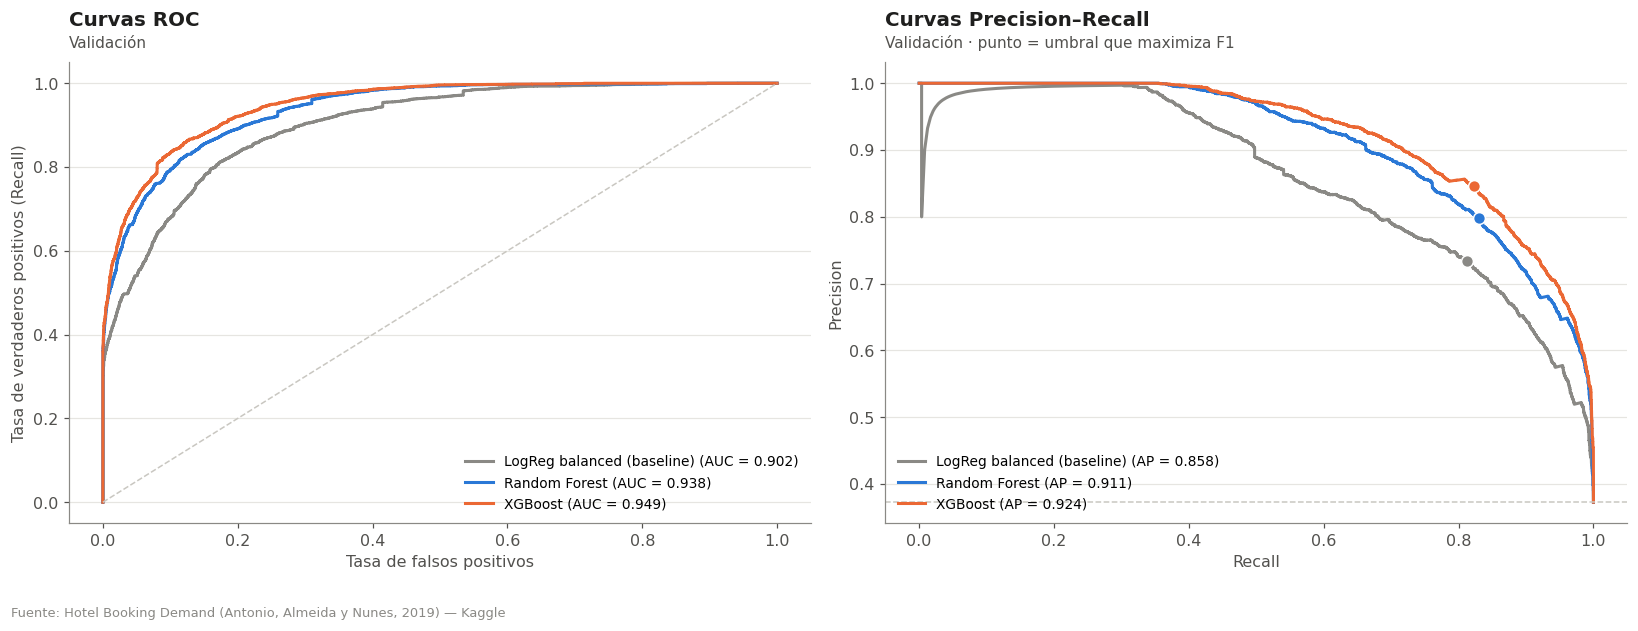

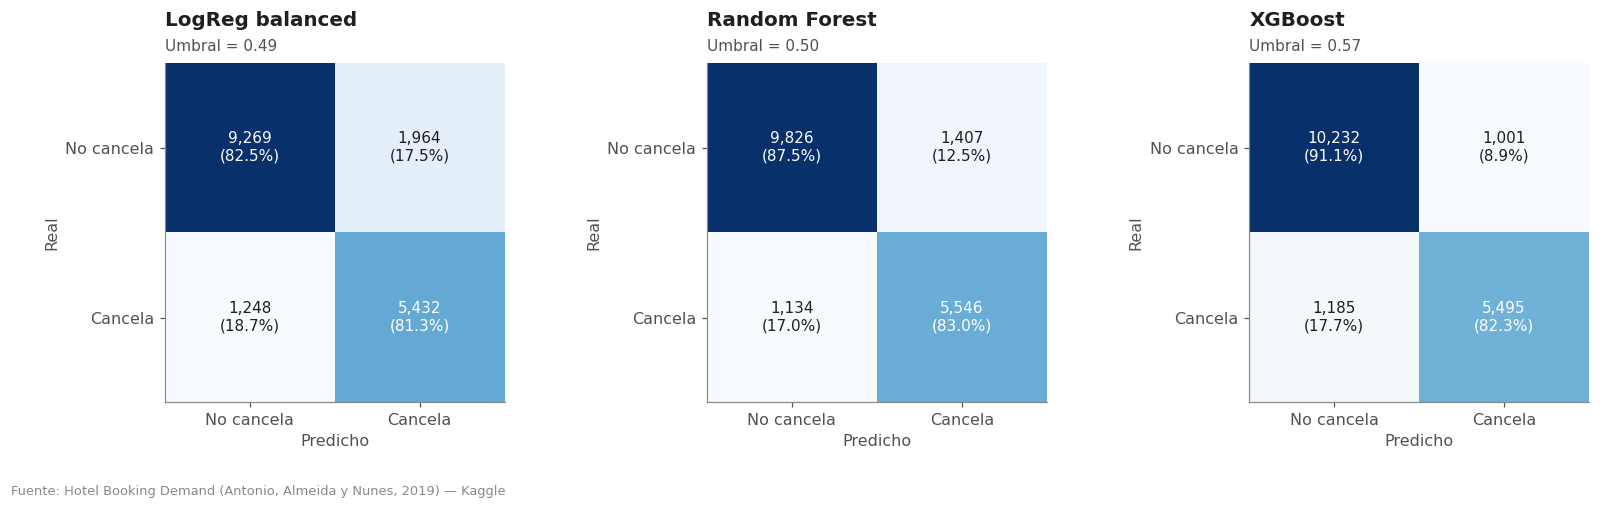

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
colores_c = {"LogReg balanced (baseline)": GRIS, "Random Forest": AZUL, "XGBoost": NARANJA}
for n, p in prob_val_c.items():
    fpr, tpr, _ = roc_curve(y_val_c, p)
    axes[0].plot(fpr, tpr, color=colores_c[n], label=f"{n} (AUC = {roc_auc_score(y_val_c, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_val_c, p)
    axes[1].plot(rc, pr, color=colores_c[n], label=f"{n} (AP = {auc(rc, pr):.3f})")
    pu = (p >= UMBRALES[n]).astype(int)
    axes[1].scatter(recall_score(y_val_c, pu), precision_score(y_val_c, pu), color=colores_c[n], s=60, zorder=3,
                    edgecolors="white")
axes[0].plot([0, 1], [0, 1], ls="--", color=GRIS_CLARO, lw=1)
axes[0].set_xlabel("Tasa de falsos positivos"); axes[0].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].axhline(y_val_c.mean(), ls="--", color=GRIS_CLARO, lw=1)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
for ax in axes: ax.legend(loc="lower left" if ax is axes[1] else "lower right", fontsize=9)
titular(axes[0], "Curvas ROC", "Validación")
titular(axes[1], "Curvas Precision–Recall", "Validación · punto = umbral que maximiza F1")
citar_fuente(fig, y=-0.05); plt.tight_layout(); guardar(fig, "4_2_roc_pr_validacion"); plt.show()

# Matrices de confusión (validación) en el umbral elegido
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, n in zip(axes, ["LogReg balanced (baseline)", "Random Forest", "XGBoost"]):
    cm = confusion_matrix(y_val_c, (prob_val_c[n] >= UMBRALES[n]).astype(int))
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}\n({v / cm[i].sum():.1%})", ha="center", va="center",
                color="white" if v > cm.max() / 2 else TINTA, fontsize=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No cancela", "Cancela"]); ax.set_yticks([0, 1])
    ax.set_yticklabels(["No cancela", "Cancela"]); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    titular(ax, n.replace(" (baseline)", ""), f"Umbral = {UMBRALES[n]:.2f}")
citar_fuente(fig, y=-0.06); plt.tight_layout(); guardar(fig, "4_2_matrices_confusion_val"); plt.show()

### 4.3 Interpretación de la clasificación
**Resultados en validación**

| Modelo | ROC-AUC | PR-AUC | F1 (umbral óptimo) | Recall (0.5) | Precision (0.5) | AUC train | Brecha |
|---|---|---|---|---|---|---|---|
| LogReg balanced (baseline) | 0.902 | 0.858 | 0.772 | 0.805 | 0.739 | 0.912 | 0.010 |
| Random Forest | 0.938 | 0.911 | 0.814 | 0.830 | 0.797 | 0.967 | 0.029 |
| **XGBoost** | **0.949** | **0.924** | **0.834** | 0.846 | 0.815 | 0.988 | 0.039 |

* **Ambos ensambles superan claramente al baseline**: XGBoost sube el ROC-AUC de 0.902 a 0.949 y el F1 de 0.772 a 0.834, mejorando **a la vez** el Recall (+4.1 pp) y la Precision (+7.6 pp). Es decir, detecta más cancelaciones con menos falsas alarmas.
* **Búsqueda de hiperparámetros.** Random Forest eligió árboles de profundidad 15 con `min_samples_leaf = 2` y `class_weight='balanced_subsample'`; XGBoost, árboles de profundidad 10 con tasa de aprendizaje baja (0.039), 866 árboles y regularización fuerte (`reg_lambda ≈ 9.3`, `gamma ≈ 0.28`). La dispersión de las configuraciones (gráfico 4.1) es estrecha: el resultado no depende de una combinación "afortunada".
* **Umbral.** El umbral que maximiza F1 en validación es cercano a 0.5 (0.50 en RF, 0.57 en XGBoost) porque la ponderación de clases ya calibra la decisión hacia la clase minoritaria; la ganancia de F1 por ajustarlo es marginal (≤ 0.004).
* **Sobreajuste.** La brecha de AUC train–val de XGBoost (0.039) es mayor que la de la regresión logística (0.010), lo esperado en un modelo más flexible, pero el AUC de validación sigue siendo el más alto y coincide con el de la validación cruzada agrupada (0.943), por lo que el modelo **generaliza**; la brecha no se traduce en pérdida de rendimiento en datos no vistos.

**Modelo seleccionado: XGBoost** con umbral 0.568.

## 5. Perceptrón Multicapa (MLP) en PyTorch

Se diseña una red neuronal *feed-forward* para el mismo problema de clasificación de cancelaciones, usando la **misma matriz preprocesada** (109 columnas estandarizadas / one-hot), para compararla en igualdad de condiciones con los modelos de árboles.

**Diseño**

| Elemento | Elección | Justificación |
|---|---|---|
| Capas ocultas | Lineal → BatchNorm → ReLU → Dropout | BatchNorm estabiliza el entrenamiento; Dropout reduce el sobreajuste |
| Salida | 1 neurona (logit) | Clasificación binaria |
| Pérdida | `BCEWithLogitsLoss(pos_weight = n_neg/n_pos)` | Equivalente a `class_weight='balanced'`; numéricamente estable |
| Optimizador | AdamW + `ReduceLROnPlateau` | Tasa de aprendizaje adaptativa con *weight decay* (regularización L2) |
| Parada temprana | Paciencia de 6 épocas sobre la pérdida de validación | Detiene el entrenamiento cuando empieza el sobreajuste y restaura los mejores pesos |

Se comparan **tres arquitecturas** (búsqueda manual de hiperparámetros) y se elige la de menor pérdida en validación.

In [ ]:
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def a_tensor(X, y=None):
    Xt = torch.tensor(np.asarray(X, dtype=np.float32))
    return Xt if y is None else (Xt, torch.tensor(np.asarray(y, dtype=np.float32)))

Xtr_t, ytr_t = a_tensor(X_train_c, y_train_c)
Xva_t, yva_t = a_tensor(X_val_c, y_val_c)

class MLP(nn.Module):
    def __init__(self, d_in, capas=(128, 64), dropout=0.3):
        super().__init__()
        bloques, prev = [], d_in
        for h in capas:
            bloques += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        bloques.append(nn.Linear(prev, 1))
        self.red = nn.Sequential(*bloques)

    def forward(self, x):
        return self.red(x).squeeze(1)

def predecir_mlp(modelo, X, lote=8192):
    modelo.eval()
    with torch.no_grad():
        return torch.cat([torch.sigmoid(modelo(X[i:i + lote].to(DEVICE))).cpu()
                          for i in range(0, len(X), lote)]).numpy()

def entrenar_mlp(capas, dropout, lr, weight_decay, epocas=EPOCAS_MLP, paciencia=6, lote=512, semilla=SEED):
    torch.manual_seed(semilla)
    modelo = MLP(Xtr_t.shape[1], capas, dropout).to(DEVICE)
    perdida = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(SPW, device=DEVICE))
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=2)
    gen = torch.Generator().manual_seed(semilla)
    cargador = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=lote, shuffle=True, generator=gen)
    hist = {"train_loss": [], "val_loss": [], "val_auc": [], "lr": []}
    mejor, mejor_estado, sin_mejora = np.inf, None, 0
    for ep in range(epocas):
        modelo.train(); acum = 0.0
        for xb, yb in cargador:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            l = perdida(modelo(xb), yb)
            l.backward(); opt.step()
            acum += l.item() * len(xb)
        modelo.eval()
        with torch.no_grad():
            logits_va = modelo(Xva_t.to(DEVICE))
            l_va = perdida(logits_va, yva_t.to(DEVICE)).item()
        hist["train_loss"].append(acum / len(Xtr_t)); hist["val_loss"].append(l_va)
        hist["val_auc"].append(roc_auc_score(y_val_c, torch.sigmoid(logits_va).cpu().numpy()))
        hist["lr"].append(opt.param_groups[0]["lr"])
        sched.step(l_va)
        if l_va < mejor - 1e-4:
            mejor, sin_mejora = l_va, 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor_estado)
    hist["mejor_epoca"] = int(np.argmin(hist["val_loss"])) + 1
    return modelo, hist

CONFIGS_MLP = {
    "MLP-A (64)":            dict(capas=(64,), dropout=0.2, lr=1e-3, weight_decay=1e-4),
    "MLP-B (128-64)":        dict(capas=(128, 64), dropout=0.3, lr=1e-3, weight_decay=1e-4),
    "MLP-C (256-128-64)":    dict(capas=(256, 128, 64), dropout=0.3, lr=1e-3, weight_decay=1e-4),
}
mlps, hists, filas_mlp = {}, {}, []
for nombre, cfg in CONFIGS_MLP.items():
    t0 = time.time()
    mlps[nombre], hists[nombre] = entrenar_mlp(**cfg)
    p_va = predecir_mlp(mlps[nombre], Xva_t)
    p_tr = predecir_mlp(mlps[nombre], Xtr_t)
    filas_mlp.append({"Arquitectura": nombre,
                      "Parámetros": sum(p.numel() for p in mlps[nombre].parameters()),
                      "Épocas": len(hists[nombre]["val_loss"]), "Mejor época": hists[nombre]["mejor_epoca"],
                      "Pérdida val": min(hists[nombre]["val_loss"]),
                      "ROC-AUC train": roc_auc_score(y_train_c, p_tr), "ROC-AUC val": roc_auc_score(y_val_c, p_va),
                      "F1 val (0.5)": f1_score(y_val_c, (p_va >= 0.5).astype(int)),
                      "Tiempo (s)": time.time() - t0})
tabla_mlp = pd.DataFrame(filas_mlp).set_index("Arquitectura")
display(tabla_mlp.style.format({"Parámetros": "{:,}", "Pérdida val": "{:.4f}", "ROC-AUC train": "{:.4f}",
                                "ROC-AUC val": "{:.4f}", "F1 val (0.5)": "{:.4f}", "Tiempo (s)": "{:.0f}"}))

MEJOR_MLP = tabla_mlp["Pérdida val"].idxmin()
mlp = mlps[MEJOR_MLP]
prob_val_c["MLP (PyTorch)"] = predecir_mlp(mlp, Xva_t)
res_c_val["MLP (PyTorch)"] = metricas_clasif(y_val_c, prob_val_c["MLP (PyTorch)"])
res_c_train["MLP (PyTorch)"] = metricas_clasif(y_train_c, predecir_mlp(mlp, Xtr_t))
UMBRALES["MLP (PyTorch)"] = umbral_optimo_f1(y_val_c, prob_val_c["MLP (PyTorch)"])[0]
print(f"Arquitectura elegida: {MEJOR_MLP} | umbral F1 en validación = {UMBRALES['MLP (PyTorch)']:.3f}")

,Parámetros,Épocas,Mejor época,Pérdida val,ROC-AUC train,ROC-AUC val,F1 val (0.5),Tiempo (s)
Arquitectura,,,,,,,,
MLP-A (64),"7,233",33,27,0.3845,0.9534,0.9399,0.8135,47
MLP-B (128-64),"22,785",18,12,0.3814,0.9540,0.9405,0.8160,23
MLP-C (256-128-64),"70,273",18,12,0.3756,0.9579,0.9432,0.8169,25


Arquitectura elegida: MLP-C (256-128-64) | umbral F1 en validación = 0.538


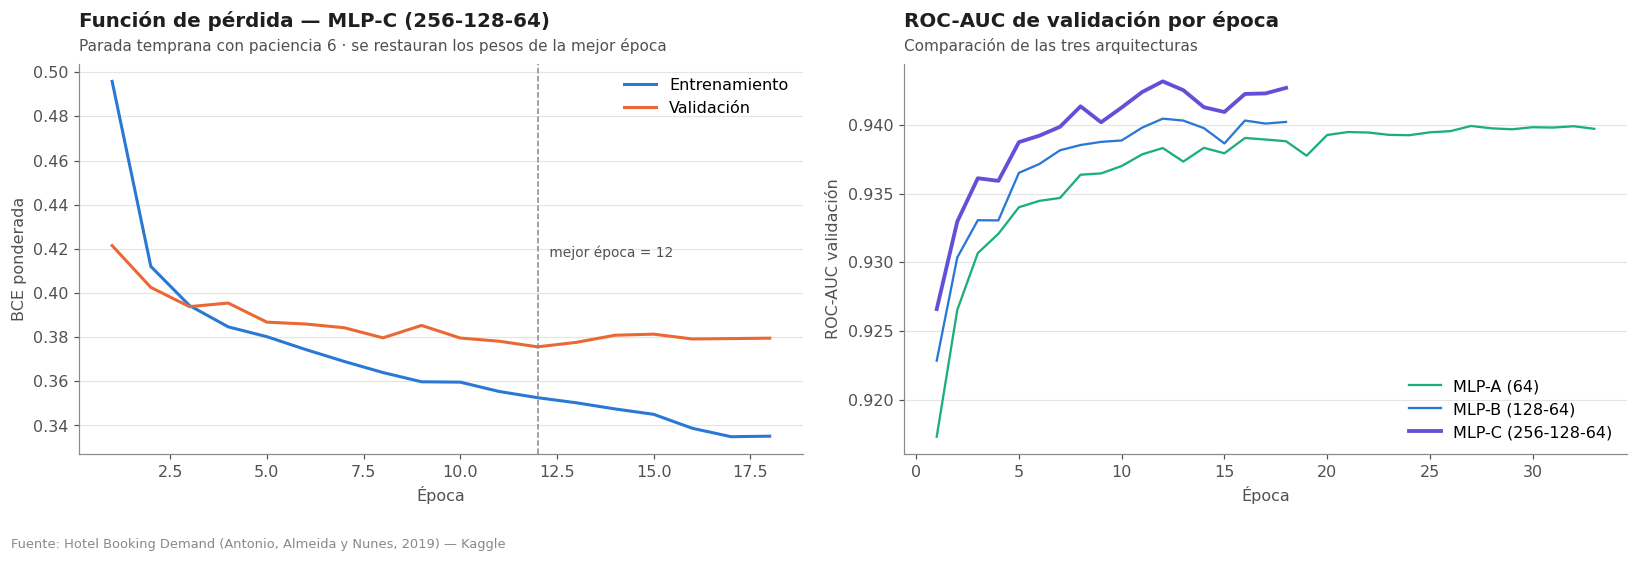

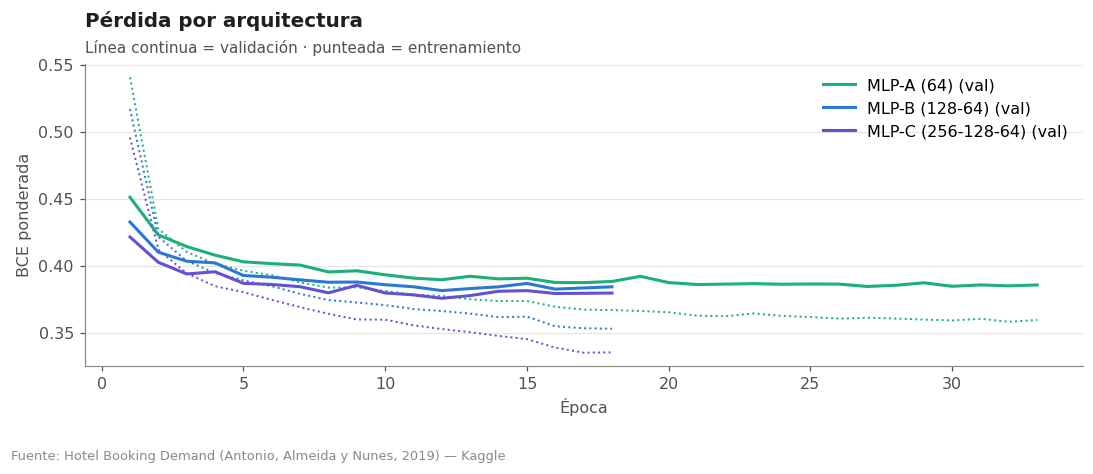

In [ ]:
# Función de pérdida (entrenamiento vs. validación) y ROC-AUC por época
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
h = hists[MEJOR_MLP]; ep = np.arange(1, len(h["train_loss"]) + 1)
axes[0].plot(ep, h["train_loss"], color=AZUL, label="Entrenamiento")
axes[0].plot(ep, h["val_loss"], color=NARANJA, label="Validación")
axes[0].axvline(h["mejor_epoca"], color=GRIS, ls="--", lw=1)
axes[0].text(h["mejor_epoca"] + 0.2, max(h["val_loss"]), f" mejor época = {h['mejor_epoca']}", color=TINTA_2, fontsize=9, va="top")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("BCE ponderada"); axes[0].legend()
titular(axes[0], f"Función de pérdida — {MEJOR_MLP}", "Parada temprana con paciencia 6 · se restauran los pesos de la mejor época")
for (n, hh), c in zip(hists.items(), [AQUA, AZUL, VIOLETA]):
    axes[1].plot(np.arange(1, len(hh["val_auc"]) + 1), hh["val_auc"], color=c, label=n,
                 lw=2.5 if n == MEJOR_MLP else 1.5)
axes[1].set_xlabel("Época"); axes[1].set_ylabel("ROC-AUC validación"); axes[1].legend()
titular(axes[1], "ROC-AUC de validación por época", "Comparación de las tres arquitecturas")
citar_fuente(fig, y=-0.05); plt.tight_layout(); guardar(fig, "5_1_mlp_curvas_perdida"); plt.show()

# Pérdida de validación de las tres arquitecturas
fig, ax = plt.subplots(figsize=(10, 4))
for (n, hh), c in zip(hists.items(), [AQUA, AZUL, VIOLETA]):
    ax.plot(np.arange(1, len(hh["val_loss"]) + 1), hh["val_loss"], color=c, label=f"{n} (val)")
    ax.plot(np.arange(1, len(hh["train_loss"]) + 1), hh["train_loss"], color=c, ls=":", lw=1.3)
ax.set_xlabel("Época"); ax.set_ylabel("BCE ponderada"); ax.legend()
titular(ax, "Pérdida por arquitectura", "Línea continua = validación · punteada = entrenamiento")
citar_fuente(fig, y=-0.06); plt.tight_layout(); guardar(fig, "5_2_mlp_arquitecturas"); plt.show()

### 5.1 Interpretación del MLP
| Arquitectura | Parámetros | Épocas (mejor) | Pérdida val | AUC train | AUC val |
|---|---|---|---|---|---|
| MLP-A (64) | 7,233 | 33 (27) | 0.3845 | 0.953 | 0.940 |
| MLP-B (128-64) | 22,785 | 18 (12) | 0.3814 | 0.954 | 0.941 |
| **MLP-C (256-128-64)** | 70,273 | 18 (12) | **0.3756** | 0.958 | **0.943** |

* **Curva de pérdida.** La pérdida de entrenamiento baja de forma continua (0.50 → 0.34), mientras que la de validación se estabiliza en ≈ 0.38 a partir de la época 8 y alcanza su mínimo (0.376) en la época 12. Desde ese punto las curvas se separan: es la señal clásica de **inicio de sobreajuste**, y la parada temprana detuvo el entrenamiento en la época 18 restaurando los pesos de la época 12. Dropout (0.3), BatchNorm y *weight decay* mantienen la brecha de AUC train–val en solo 0.015.
* **Capacidad.** Aumentar la red de 7 mil a 70 mil parámetros mejora el AUC de validación en apenas 0.003: el problema está cerca del techo de lo que la información disponible permite separar con una red densa.
* **Comparación.** El MLP (AUC val 0.943) supera ampliamente al baseline lineal (0.902) y queda entre Random Forest (0.938) y XGBoost (0.949). Es coherente con la literatura: en datos **tabulares** con muchas variables categóricas, los ensambles de árboles suelen igualar o superar a las redes densas, con menor costo de ajuste y mejor interpretabilidad. El MLP se conserva como modelo alternativo y como evidencia de que la señal no es exclusiva de un algoritmo.

## 6. Aprendizaje no supervisado: segmentación de reservas

**Objetivo:** descubrir **perfiles de reserva** a partir de sus características cuantitativas, *sin usar* la etiqueta de cancelación, y verificar después si los perfiles tienen distinto riesgo de cancelación y distinto valor (ADR). Esto permite diseñar políticas por segmento (depósitos, tarifas, comunicación).

**Variables de segmentación** (cuantitativas, disponibles al momento de reservar):

| Variable | Tratamiento | Qué describe |
|---|---|---|
| `lead_time` | log1p | Anticipación de la reserva |
| `adr` | Winsorización p99 | Tarifa diaria (valor) |
| `total_noches` | Winsorización p99 | Duración de la estancia |
| `total_huespedes` | — | Tamaño del grupo |
| `prop_fin_semana` | — | Perfil vacacional vs. de semana |
| `total_of_special_requests` | — | Compromiso / personalización |

Después de las transformaciones, todas se **estandarizan** (K-Means usa distancia euclídea, por lo que una variable en euros dominaría a una proporción). El preprocesador se ajusta **solo en train** y se aplica a validación y prueba.

In [ ]:
VARS_CLUST = ["lead_time", "adr", "total_noches", "total_huespedes", "prop_fin_semana", "total_of_special_requests"]
prep_clust = crear_preprocesador_clustering(VARS_CLUST).fit(df_train[VARS_CLUST])
Z_train = prep_clust.transform(df_train[VARS_CLUST])
Z_val   = prep_clust.transform(df_val[VARS_CLUST])
Z_test  = prep_clust.transform(df_test[VARS_CLUST])
print("Matriz de clustering (train):", Z_train.shape)

# Muestra fija para métricas O(n²) (silueta) y para el jerárquico
rng = np.random.default_rng(SEED)
idx_sil = rng.choice(len(Z_train), size=15_000, replace=False)

filas_k, modelos_k = [], {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_train)
    modelos_k[k] = km
    filas_k.append({"K": k, "Inercia (SSE)": km.inertia_,
                    "Silueta": silhouette_score(Z_train[idx_sil], km.labels_[idx_sil]),
                    "Davies-Bouldin": davies_bouldin_score(Z_train[idx_sil], km.labels_[idx_sil]),
                    "Calinski-Harabasz": calinski_harabasz_score(Z_train, km.labels_)})
tabla_k = pd.DataFrame(filas_k).set_index("K")
# Codo: punto de máxima distancia a la recta que une el primer y el último punto de la curva SSE
x = tabla_k.index.values.astype(float); y = tabla_k["Inercia (SSE)"].values
xn, yn = (x - x.min()) / (x.max() - x.min()), (y - y.min()) / (y.max() - y.min())
K_CODO = int(x[np.argmax(np.abs(yn - (1 - xn)))])
display(tabla_k.style.format({"Inercia (SSE)": "{:,.0f}", "Silueta": "{:.3f}", "Davies-Bouldin": "{:.3f}",
                              "Calinski-Harabasz": "{:,.0f}"})
        .highlight_max(subset=["Silueta", "Calinski-Harabasz"], color="#d9ecff")
        .highlight_min(subset=["Davies-Bouldin"], color="#d9ecff"))
print(f"K sugerido por el codo (máxima distancia a la cuerda): {K_CODO}")
print(f"K con mayor silueta: {int(tabla_k['Silueta'].idxmax())}")

Matriz de clustering (train): (83610, 6)


,Inercia (SSE),Silueta,Davies-Bouldin,Calinski-Harabasz
K,,,,
2,"416,640",0.196,2.041,"17,061"
3,"357,825",0.197,1.770,"16,804"
4,"317,278",0.191,1.573,"16,196"
5,"278,879",0.202,1.414,"16,697"
6,"249,327",0.220,1.346,"16,922"
7,"230,253",0.206,1.412,"16,424"
8,"217,514",0.207,1.406,"15,602"
9,"207,502",0.209,1.373,"14,814"
10,"199,598",0.211,1.422,"14,057"


K sugerido por el codo (máxima distancia a la cuerda): 6
K con mayor silueta: 6


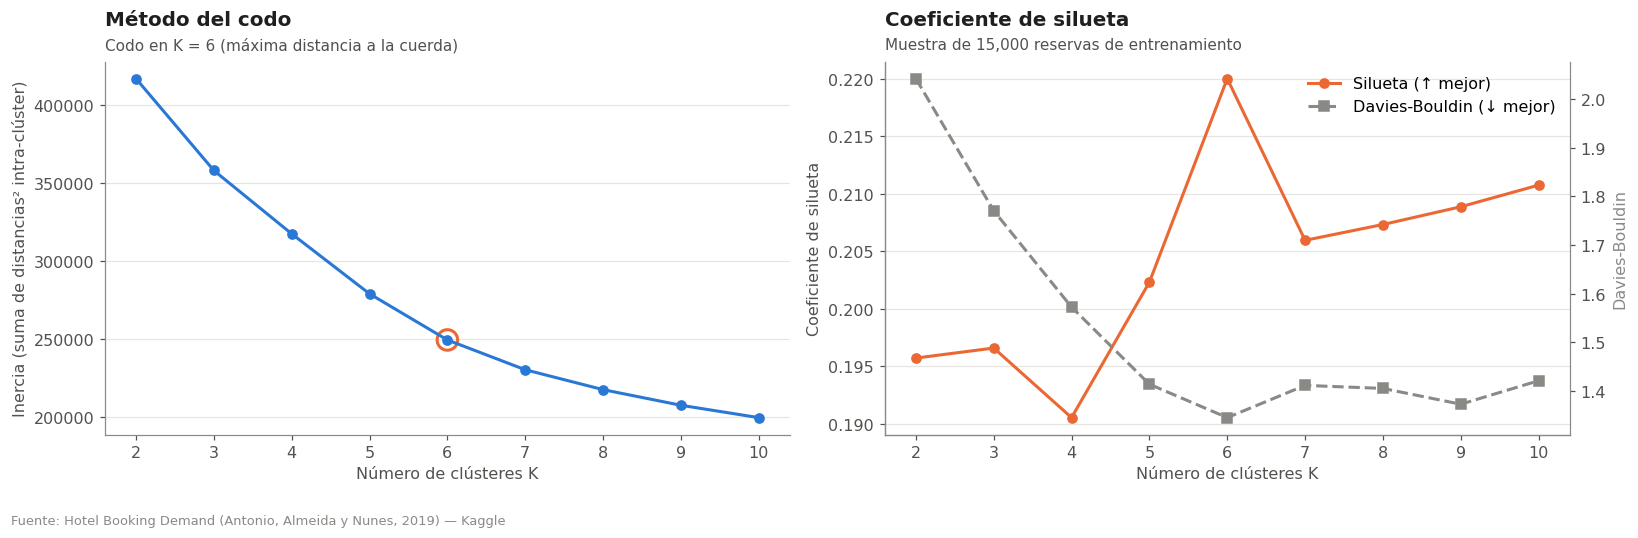

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].plot(tabla_k.index, tabla_k["Inercia (SSE)"], marker="o", color=AZUL)
axes[0].scatter([K_CODO], [tabla_k.loc[K_CODO, "Inercia (SSE)"]], s=180, facecolors="none", edgecolors=NARANJA, lw=2)
axes[0].set_xlabel("Número de clústeres K"); axes[0].set_ylabel("Inercia (suma de distancias² intra-clúster)")
titular(axes[0], "Método del codo", f"Codo en K = {K_CODO} (máxima distancia a la cuerda)")
axes[1].plot(tabla_k.index, tabla_k["Silueta"], marker="o", color=NARANJA, label="Silueta (↑ mejor)")
ax2 = axes[1].twinx(); ax2.plot(tabla_k.index, tabla_k["Davies-Bouldin"], marker="s", color=GRIS, ls="--", label="Davies-Bouldin (↓ mejor)")
ax2.spines["right"].set_visible(True); ax2.grid(False); ax2.set_ylabel("Davies-Bouldin", color=GRIS)
axes[1].set_xlabel("Número de clústeres K"); axes[1].set_ylabel("Coeficiente de silueta")
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc="upper right")
titular(axes[1], "Coeficiente de silueta", "Muestra de 15,000 reservas de entrenamiento")
citar_fuente(fig, y=-0.05); plt.tight_layout(); guardar(fig, "6_1_codo_silueta"); plt.show()

### 6.1 Selección de K
Las tres señales internas coinciden en **K = 6**:

* **Codo:** la curva de inercia cae rápido hasta K = 6 (de 416,640 a 249,327) y luego se aplana (230 mil, 218 mil, 208 mil…); el criterio de máxima distancia a la cuerda marca K = 6.
* **Silueta:** máximo en K = 6 (0.220).
* **Davies-Bouldin:** mínimo en K = 6 (1.346).

La silueta es **moderada** (≈ 0.22): las reservas no forman grupos compactos y separados, sino un continuo con zonas de mayor densidad. Es habitual en datos de comportamiento de clientes, y por eso la validez de la segmentación se juzga también por su **estabilidad** y su **valor práctico** (Bloque 6.3), no solo por la silueta.

In [ ]:
K_SIL = int(tabla_k["Silueta"].idxmax()); K_DB = int(tabla_k["Davies-Bouldin"].idxmin())
K_OPT = K_SIL   # criterio principal: máxima silueta; se verifica su coherencia con el codo y Davies-Bouldin
print(f"K por silueta = {K_SIL} | K por codo = {K_CODO} | K por Davies-Bouldin = {K_DB} -> K elegido = {K_OPT}")
kmeans = modelos_k[K_OPT]

# Reordenar etiquetas por ADR medio (0 = menor ADR) para que la numeración sea estable e interpretable
adr_medio = pd.Series(df_train["adr"].values).groupby(kmeans.labels_).mean().sort_values()
MAPA = {int(viejo): int(nuevo) for nuevo, viejo in enumerate(adr_medio.index)}
LUT = np.array([MAPA[i] for i in range(K_OPT)])
etiquetar = lambda Z: LUT[kmeans.predict(Z)]
cl_train, cl_val, cl_test = etiquetar(Z_train), etiquetar(Z_val), etiquetar(Z_test)

print(f"K-Means con K = {K_OPT} | silueta (muestra train) = {silhouette_score(Z_train[idx_sil], cl_train[idx_sil]):.3f}")
print("Tamaño de los clústeres en train:", pd.Series(cl_train).value_counts().sort_index().to_dict())

K por silueta = 6 | K por codo = 6 | K por Davies-Bouldin = 6 -> K elegido = 6
K-Means con K = 6 | silueta (muestra train) = 0.220
Tamaño de los clústeres en train: {0: 12354, 1: 15876, 2: 11385, 3: 26394, 4: 9145, 5: 8456}


### 6.2 Segundo algoritmo: Clustering Jerárquico Aglomerativo (Ward)
El enlace de **Ward** fusiona en cada paso los dos grupos que menos aumentan la varianza intra-clúster, que es el mismo criterio que optimiza K-Means; por eso es el contraste natural. Su costo de memoria es O(n²), así que se ajusta sobre una **muestra aleatoria de 6,000 reservas** de entrenamiento. Se analiza el dendrograma, se evalúa la silueta para varios cortes y se mide el acuerdo con K-Means mediante el **Índice de Rand Ajustado (ARI)**.

,Silueta,Davies-Bouldin
K,,
2,0.192,2.106
3,0.148,2.044
4,0.163,1.740
5,0.163,1.602
6,0.181,1.551
7,0.172,1.606
8,0.135,1.520


,Silueta,Davies-Bouldin,Calinski-Harabasz
Algoritmo,,,
K-Means,0.224,1.329,1221.134
Aglomerativo (Ward),0.181,1.551,970.438


Acuerdo K-Means vs. Aglomerativo (ARI) = 0.413
Tabla de contingencia (filas = K-Means, columnas = Aglomerativo):


Aglomerativo,0,1,2,3,4,5
K-Means,,,,,,
0,91,748,24,6,9,31
1,464,65,55,354,0,210
2,124,0,46,0,617,27
3,1435,54,64,0,11,308
4,46,23,21,16,37,508
5,0,18,493,2,3,90


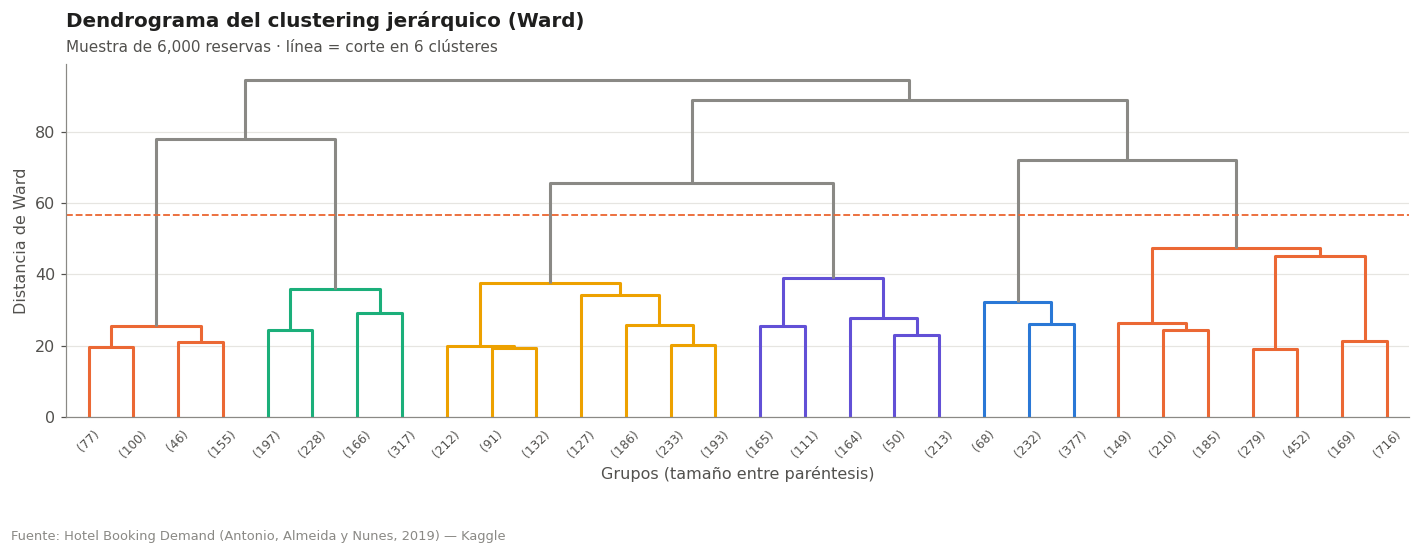

In [ ]:
idx_h = rng.choice(len(Z_train), size=6_000, replace=False)
Zh = Z_train[idx_h]

# Árbol completo (scipy) para el dendrograma y para evaluar distintos cortes
L = linkage(Zh, method="ward")
filas_h = []
for k in range(2, 9):
    lab = fcluster(L, t=k, criterion="maxclust")
    filas_h.append({"K": k, "Silueta": silhouette_score(Zh, lab), "Davies-Bouldin": davies_bouldin_score(Zh, lab)})
tabla_h = pd.DataFrame(filas_h).set_index("K")

# Modelo de scikit-learn con el mismo K que K-Means
agg = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward").fit(Zh)
comp = pd.DataFrame({
    "Algoritmo": ["K-Means", "Aglomerativo (Ward)"],
    "Silueta": [silhouette_score(Zh, cl_train[idx_h]), silhouette_score(Zh, agg.labels_)],
    "Davies-Bouldin": [davies_bouldin_score(Zh, cl_train[idx_h]), davies_bouldin_score(Zh, agg.labels_)],
    "Calinski-Harabasz": [calinski_harabasz_score(Zh, cl_train[idx_h]), calinski_harabasz_score(Zh, agg.labels_)],
}).set_index("Algoritmo")
ARI = adjusted_rand_score(cl_train[idx_h], agg.labels_)
display(tabla_h.style.format("{:.3f}").set_caption("Jerárquico: calidad según el número de clústeres (muestra 6,000)"))
display(comp.style.format("{:.3f}").set_caption(f"Comparación con K = {K_OPT} sobre la misma muestra"))
print(f"Acuerdo K-Means vs. Aglomerativo (ARI) = {ARI:.3f}")
print("Tabla de contingencia (filas = K-Means, columnas = Aglomerativo):")
display(pd.crosstab(pd.Series(cl_train[idx_h], name="K-Means"), pd.Series(agg.labels_, name="Aglomerativo")))

fig, ax = plt.subplots(figsize=(13, 4.6))
CORTE = (L[-K_OPT, 2] + L[-(K_OPT - 1), 2]) / 2
dendrogram(L, truncate_mode="lastp", p=30, ax=ax, color_threshold=CORTE,
           above_threshold_color=GRIS, leaf_font_size=8)
ax.axhline(CORTE, color=NARANJA, ls="--", lw=1.2)
ax.set_xlabel("Grupos (tamaño entre paréntesis)"); ax.set_ylabel("Distancia de Ward")
titular(ax, "Dendrograma del clustering jerárquico (Ward)", f"Muestra de 6,000 reservas · línea = corte en {K_OPT} clústeres")
citar_fuente(fig, y=-0.08); plt.tight_layout(); guardar(fig, "6_2_dendrograma"); plt.show()

### 6.3 Perfiles de los clústeres y valor práctico
Los perfiles se describen en las **unidades originales** (días, euros, noches) y se cruzan con variables que **no** se usaron para segmentar: tasa de cancelación, tipo de hotel, segmento de mercado y presencia de niños.

In [ ]:
def perfil(df, etiquetas):
    d = df.assign(cluster=etiquetas)
    p = d.groupby("cluster").agg(
        n=("adr", "size"), lead_time=("lead_time", "mean"), adr=("adr", "mean"), total_noches=("total_noches", "mean"),
        total_huespedes=("total_huespedes", "mean"), prop_fin_semana=("prop_fin_semana", "mean"),
        peticiones=("total_of_special_requests", "mean"), cancelacion=("is_canceled", "mean"),
        pct_resort=("hotel", lambda s: (s == "Resort Hotel").mean()), pct_ninos=("con_ninos", "mean"),
        pct_deposito=("deposit_type", lambda s: (s != "No Deposit").mean()),
        segmento_principal=("market_segment", lambda s: s.value_counts().index[0]))
    p.insert(1, "% reservas", p["n"] / p["n"].sum())
    p["ingreso_estancia"] = p["adr"] * p["total_noches"]
    return p

perfil_train = perfil(df_train, cl_train)
fmt = {"n": "{:,}", "% reservas": "{:.1%}", "lead_time": "{:.0f} d", "adr": "{:.1f} €", "total_noches": "{:.2f}",
       "total_huespedes": "{:.2f}", "prop_fin_semana": "{:.2f}", "peticiones": "{:.2f}", "cancelacion": "{:.1%}",
       "pct_resort": "{:.1%}", "pct_ninos": "{:.1%}", "pct_deposito": "{:.1%}", "ingreso_estancia": "{:.0f} €"}
display(perfil_train.style.format(fmt).background_gradient(subset=["cancelacion"], cmap="Oranges")
        .set_caption("Perfil de los clústeres (entrenamiento)"))

# Estabilidad: ¿se mantienen tamaño y riesgo en datos no vistos?
estab = pd.DataFrame({
    "% train": pd.Series(cl_train).value_counts(normalize=True).sort_index(),
    "% test": pd.Series(cl_test).value_counts(normalize=True).sort_index(),
    "Cancelación train": df_train["is_canceled"].groupby(cl_train).mean(),
    "Cancelación test": df_test["is_canceled"].groupby(cl_test).mean(),
})
display(estab.style.format("{:.1%}").set_caption("Estabilidad de los clústeres: entrenamiento vs. prueba"))
print(f"Silueta en prueba (muestra): {silhouette_score(Z_test, cl_test, sample_size=10_000, random_state=SEED):.3f}")

,n,% reservas,lead_time,adr,total_noches,total_huespedes,prop_fin_semana,peticiones,cancelacion,pct_resort,pct_ninos,pct_deposito,segmento_principal,ingreso_estancia
cluster,,,,,,,,,,,,,,
0,"12,354",14.8%,5 d,79.5 €,1.81,1.54,0.06,0.41,12.0%,45.2%,1.6%,1.0%,Online TA,144 €
1,"15,876",19.0%,97 d,91.1 €,2.52,1.84,0.68,0.36,38.5%,25.2%,2.3%,14.1%,Online TA,230 €
2,"11,385",13.6%,137 d,91.9 €,7.76,1.92,0.30,0.46,35.6%,62.2%,3.6%,6.0%,Online TA,713 €
3,"26,394",31.6%,153 d,93.5 €,2.64,1.85,0.08,0.24,53.4%,17.8%,1.2%,29.1%,Online TA,247 €
4,"9,145",10.9%,93 d,115.2 €,3.69,2.13,0.25,2.19,22.5%,33.3%,11.7%,0.0%,Online TA,425 €
5,"8,456",10.1%,82 d,184.5 €,3.82,3.14,0.24,0.66,40.8%,42.2%,50.2%,0.7%,Online TA,704 €


,% train,% test,Cancelación train,Cancelación test
0,14.8%,15.0%,12.0%,11.6%
1,19.0%,19.3%,38.5%,36.8%
2,13.6%,14.1%,35.6%,37.6%
3,31.6%,30.9%,53.4%,48.2%
4,10.9%,10.9%,22.5%,21.5%
5,10.1%,9.7%,40.8%,40.3%


Silueta en prueba (muestra): 0.222


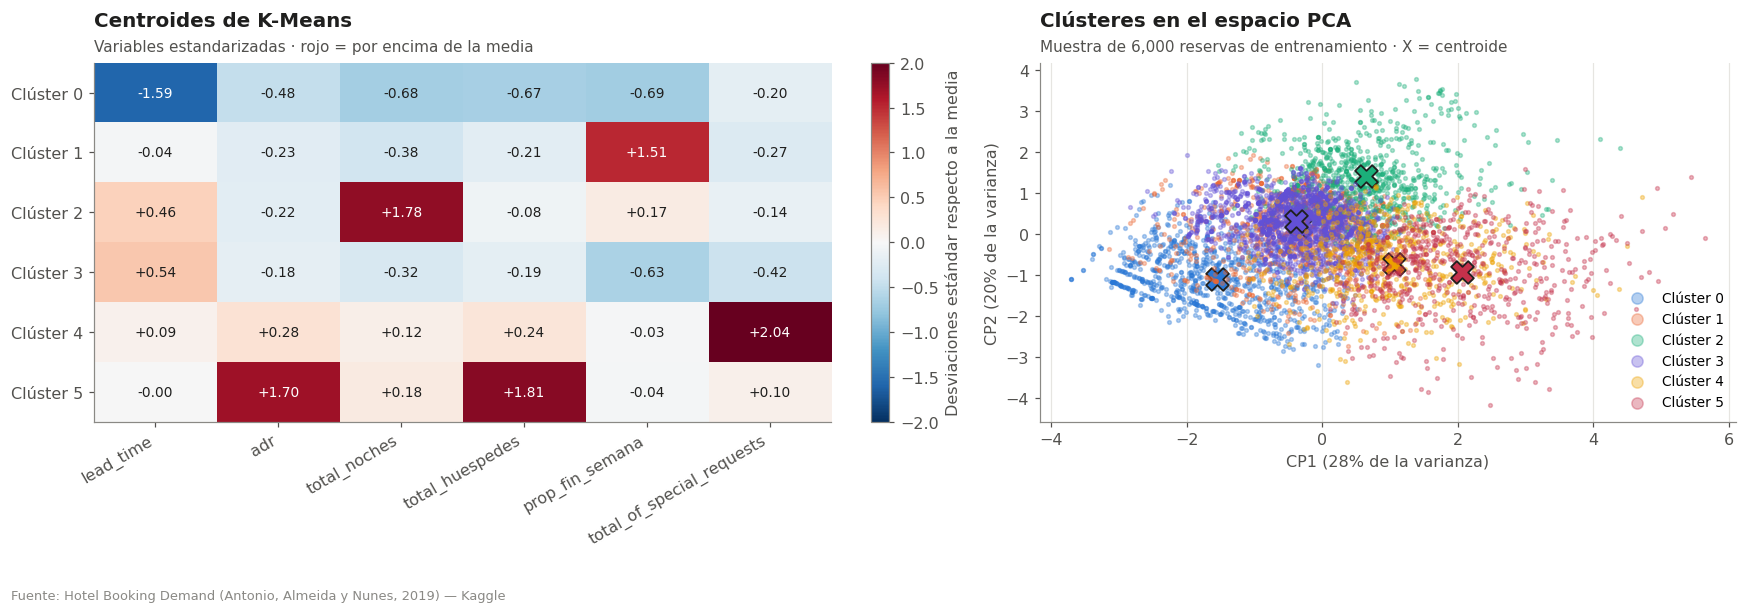

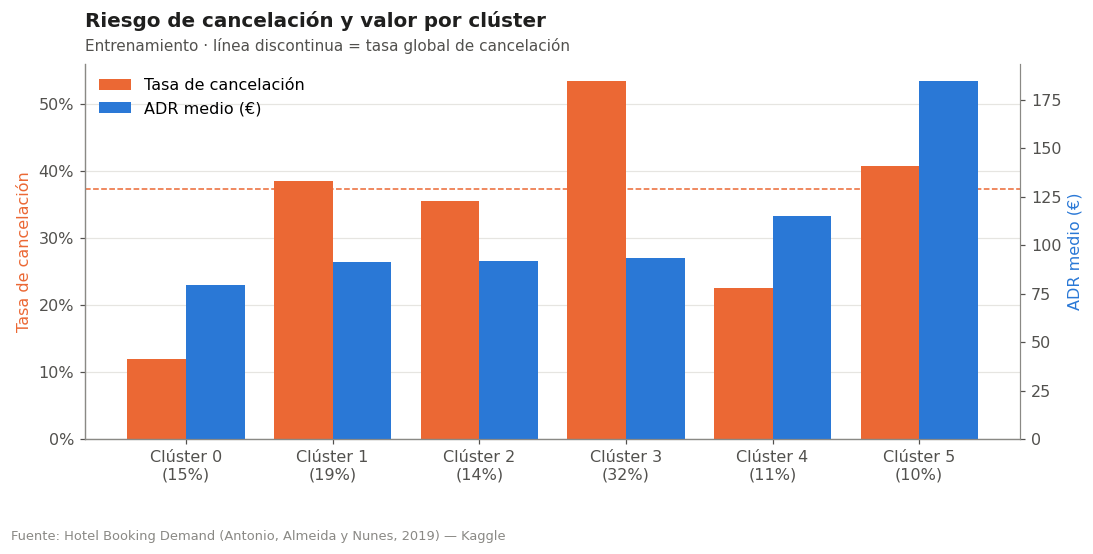

In [ ]:
# Mapa de calor de los centroides estandarizados (en el orden de etiquetas reordenado)
centros = pd.DataFrame(kmeans.cluster_centers_, columns=VARS_CLUST)
centros.index = [MAPA[i] for i in centros.index]; centros = centros.sort_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(centros.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
axes[0].grid(False)
axes[0].set_xticks(range(len(VARS_CLUST))); axes[0].set_xticklabels(VARS_CLUST, rotation=30, ha="right")
axes[0].set_yticks(range(K_OPT)); axes[0].set_yticklabels([f"Clúster {i}" for i in range(K_OPT)])
for (i, j), v in np.ndenumerate(centros.values):
    axes[0].text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 1.1 else TINTA)
fig.colorbar(im, ax=axes[0], fraction=0.03, label="Desviaciones estándar respecto a la media")
titular(axes[0], "Centroides de K-Means", "Variables estandarizadas · rojo = por encima de la media")

# Proyección PCA 2D
pca = PCA(n_components=2, random_state=SEED).fit(Z_train)
P = pca.transform(Z_train[idx_h]); C = pca.transform(centros.values)
for k in range(K_OPT):
    m = cl_train[idx_h] == k
    axes[1].scatter(P[m, 0], P[m, 1], s=6, alpha=0.35, color=PALETA_CLUSTER[k], label=f"Clúster {k}")
    axes[1].scatter(C[k, 0], C[k, 1], s=220, marker="X", color=PALETA_CLUSTER[k], edgecolors=TINTA, lw=1.2)
axes[1].set_xlabel(f"CP1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
axes[1].set_ylabel(f"CP2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)")
axes[1].legend(markerscale=3, loc="best", fontsize=9); axes[1].grid(axis="both")
titular(axes[1], "Clústeres en el espacio PCA", "Muestra de 6,000 reservas de entrenamiento · X = centroide")
citar_fuente(fig, y=-0.06); plt.tight_layout(); guardar(fig, "6_3_centroides_pca"); plt.show()

# Riesgo y valor por clúster
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(K_OPT)
ax.bar(x - 0.2, perfil_train["cancelacion"], width=0.4, color=NARANJA, label="Tasa de cancelación")
ax.axhline(df_train["is_canceled"].mean(), color=NARANJA, ls="--", lw=1)
ax2 = ax.twinx(); ax2.bar(x + 0.2, perfil_train["adr"], width=0.4, color=AZUL, label="ADR medio (€)")
ax2.spines["right"].set_visible(True); ax2.grid(False); ax2.set_ylabel("ADR medio (€)", color=AZUL)
ax.set_ylabel("Tasa de cancelación", color=NARANJA); ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xticks(x); ax.set_xticklabels([f"Clúster {i}\n({perfil_train['% reservas'].iloc[i]:.0%})" for i in x])
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper left")
titular(ax, "Riesgo de cancelación y valor por clúster", "Entrenamiento · línea discontinua = tasa global de cancelación")
citar_fuente(fig, y=-0.08); plt.tight_layout(); guardar(fig, "6_3_riesgo_valor_cluster"); plt.show()

### 6.4 Interpretación de los segmentos
**Validación de la segmentación**

* **Segundo algoritmo.** El jerárquico de Ward también encuentra su mejor estructura en K = 6 dentro del rango 3–8 (silueta 0.181, la más alta después de K = 2) y coincide parcialmente con K-Means (ARI = 0.41). K-Means obtiene mejores índices internos sobre la misma muestra (silueta 0.224 frente a 0.181; Davies-Bouldin 1.33 frente a 1.55) y además **asigna reservas nuevas** con `predict`, cosa que el aglomerativo no permite. Por eso K-Means es la segmentación operativa y el jerárquico actúa como contraste: los segmentos de último minuto, estancias largas y familias/premium aparecen en ambos (filas casi puras en la tabla de contingencia), mientras que los grupos intermedios se reparten de forma distinta.
* **Estabilidad.** Aplicados a prueba, los clústeres conservan su tamaño (diferencias ≤ 0.7 pp), su riesgo relativo de cancelación y la silueta (0.222 frente a 0.220 en train). La segmentación es reproducible en datos no vistos.

**Perfiles (entrenamiento)**

| Clúster | Nombre propuesto | % | Rasgos | ADR | Cancelación | Acción sugerida |
|---|---|---|---|---|---|---|
| 0 | **Último minuto** | 14.8 % | Reservan con 5 días, 1.8 noches, 1.5 huéspedes | 79.5 € | **12.0 %** | Segmento seguro: liberar inventario para él cerca de la fecha |
| 1 | **Escapadas de fin de semana** | 19.0 % | 68 % de noches en fin de semana, 2.5 noches | 91.1 € | 38.5 % | Recordatorios previos a la llegada |
| 2 | **Estancias largas vacacionales** | 13.6 % | 7.8 noches, 62 % Resort, 137 días de antelación | 91.9 € | 35.6 % | Mayor ingreso por estancia (≈ 713 €): proteger con depósito parcial |
| 3 | **Anticipadas entre semana** | 31.6 % | 153 días de antelación, casi sin fin de semana ni peticiones | 93.5 € | **53.4 %** | Segmento de mayor riesgo: *overbooking* controlado y confirmación activa |
| 4 | **Clientes comprometidos** | 10.9 % | 2.2 peticiones especiales en promedio | 115.2 € | **22.5 %** | Fidelizar; bajo riesgo pese a no pagar depósito |
| 5 | **Familias / grupos premium** | 10.1 % | 3.1 huéspedes, 50 % con niños | **184.5 €** | 40.8 % | Alto valor (≈ 704 €/estancia): políticas de flexibilidad con depósito |

**Valor práctico.** Sin usar la etiqueta, la segmentación separa perfiles cuya tasa de cancelación va del **12 % al 53 %** (más de 4 veces) y cuyo valor por estancia va de 144 € a 713 €. Dos hallazgos son especialmente útiles:

1. El **riesgo se concentra en las reservas anticipadas sin compromiso** (clúster 3, un tercio de las reservas y más de la mitad canceladas), y el compromiso del cliente (peticiones especiales, clúster 4) es un indicador de estancia segura. Esto coincide con lo que encuentran los modelos supervisados (`lead_time` y `total_of_special_requests` aparecen entre las variables más importantes en SHAP).
2. El clúster 3 tiene la mayor proporción de depósitos (29 %) y aun así la mayor cancelación. Es una peculiaridad conocida de este dataset: las reservas *Non Refund* (en su mayoría de grupos y del City Hotel, en Portugal) cancelan casi siempre; no deben leerse como "el depósito aumenta la cancelación", sino como un tipo de reserva grupal con un comportamiento particular.

Los clústeres y sus perfiles quedan guardados para el **módulo de segmentación del dashboard** (Fase 4).

## 7. Interpretabilidad

Se combinan tres técnicas complementarias:

1. **SHAP (TreeExplainer)** sobre XGBoost: descompone cada predicción en la contribución de cada variable (valores de Shapley). Da importancia **global** (media de |SHAP|) y la **dirección** del efecto.
2. **Importancia por permutación** sobre el *pipeline completo* (preprocesador + modelo) y las variables **originales**: mide cuánto cae el ROC-AUC de validación al desordenar cada variable. Es agnóstica al modelo y no sufre el sesgo de la importancia por impureza hacia variables con muchas categorías.
3. **Ablación de `country`** (compromiso de la Fase 2): se reentrena el mejor clasificador sin esa variable para medir cuánto de su rendimiento depende de ella.

Las columnas *one-hot* se **agregan** a su variable original (p. ej., todas las `country_*` → `country`) para que las importancias sean comparables.

In [ ]:
def variable_original(col):
    """'cat__country_PRT' -> 'country'; 'other_num__adults' -> 'adults'; 'lead_time_t__lead_time' -> 'lead_time'."""
    resto = col.split("__", 1)[1]
    if col.startswith("cat__"):
        return next(v for v in CAT_VARS if resto.startswith(v + "_"))
    return resto

ORIG_C = pd.Series({c: variable_original(c) for c in FEATS_C})
ORIG_R = pd.Series({c: variable_original(c) for c in FEATS_R})

idx_shap = rng.choice(len(X_val_c), size=3_000, replace=False)
Xs_c = X_val_c.iloc[idx_shap]
if SHAP_OK:
    expl_c = shap.TreeExplainer(modelos_c["XGBoost"])
    sv_c = expl_c.shap_values(Xs_c)
else:  # respaldo: contribuciones nativas de XGBoost (también son valores SHAP exactos para árboles)
    sv_c = modelos_c["XGBoost"].get_booster().predict(xgboost.DMatrix(Xs_c), pred_contribs=True)[:, :-1]
shap_c = pd.DataFrame(np.abs(sv_c), columns=FEATS_C).T.groupby(ORIG_C).sum().T.mean().sort_values(ascending=False)

# Importancia por permutación sobre variables ORIGINALES (pipeline completo), en una muestra de validación
pipe_xgb_c = Pipeline([("pre", preproc_clasif), ("model", modelos_c["XGBoost"])])
idx_perm = rng.choice(len(df_val), size=8_000, replace=False)
t0 = time.time()
perm = permutation_importance(pipe_xgb_c, df_val.iloc[idx_perm][vars_clasif], y_val_c.iloc[idx_perm],
                              scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=N_JOBS)
perm_c = pd.Series(perm.importances_mean, index=vars_clasif).sort_values(ascending=False)
print(f"Permutación: {time.time() - t0:.0f} s")

# Importancia por impureza del Random Forest (agregada)
imp_rf = pd.Series(modelos_c["Random Forest"].feature_importances_, index=FEATS_C).groupby(ORIG_C).sum()

imp = pd.DataFrame({"|SHAP| medio (XGB)": shap_c, "Δ ROC-AUC permutación (XGB)": perm_c,
                    "Impureza (RF)": imp_rf}).sort_values("|SHAP| medio (XGB)", ascending=False)
imp["Rango SHAP"] = imp["|SHAP| medio (XGB)"].rank(ascending=False).astype(int)
imp["Rango permutación"] = imp["Δ ROC-AUC permutación (XGB)"].rank(ascending=False).astype(int)
imp["Rango RF"] = imp["Impureza (RF)"].rank(ascending=False).astype(int)
display(imp.head(15).style.format({"|SHAP| medio (XGB)": "{:.3f}", "Δ ROC-AUC permutación (XGB)": "{:.4f}",
                                   "Impureza (RF)": "{:.3f}"}))

Permutación: 62 s


,|SHAP| medio (XGB),Δ ROC-AUC permutación (XGB),Impureza (RF),Rango SHAP,Rango permutación,Rango RF
country,1.340,0.1053,0.147,1,1,2
deposit_type,1.107,0.0735,0.229,2,2,1
agent,0.685,0.0485,0.086,3,3,4
market_segment,0.585,0.0444,0.062,4,4,6
total_of_special_requests,0.501,0.0348,0.067,5,7,5
lead_time,0.443,0.0362,0.108,6,5,3
required_car_parking_spaces,0.437,0.0358,0.045,7,6,7
customer_type,0.398,0.0259,0.034,8,10,9
previous_cancellations,0.279,0.0284,0.037,9,8,8
arrival_date_year,0.259,0.0265,0.028,10,9,10


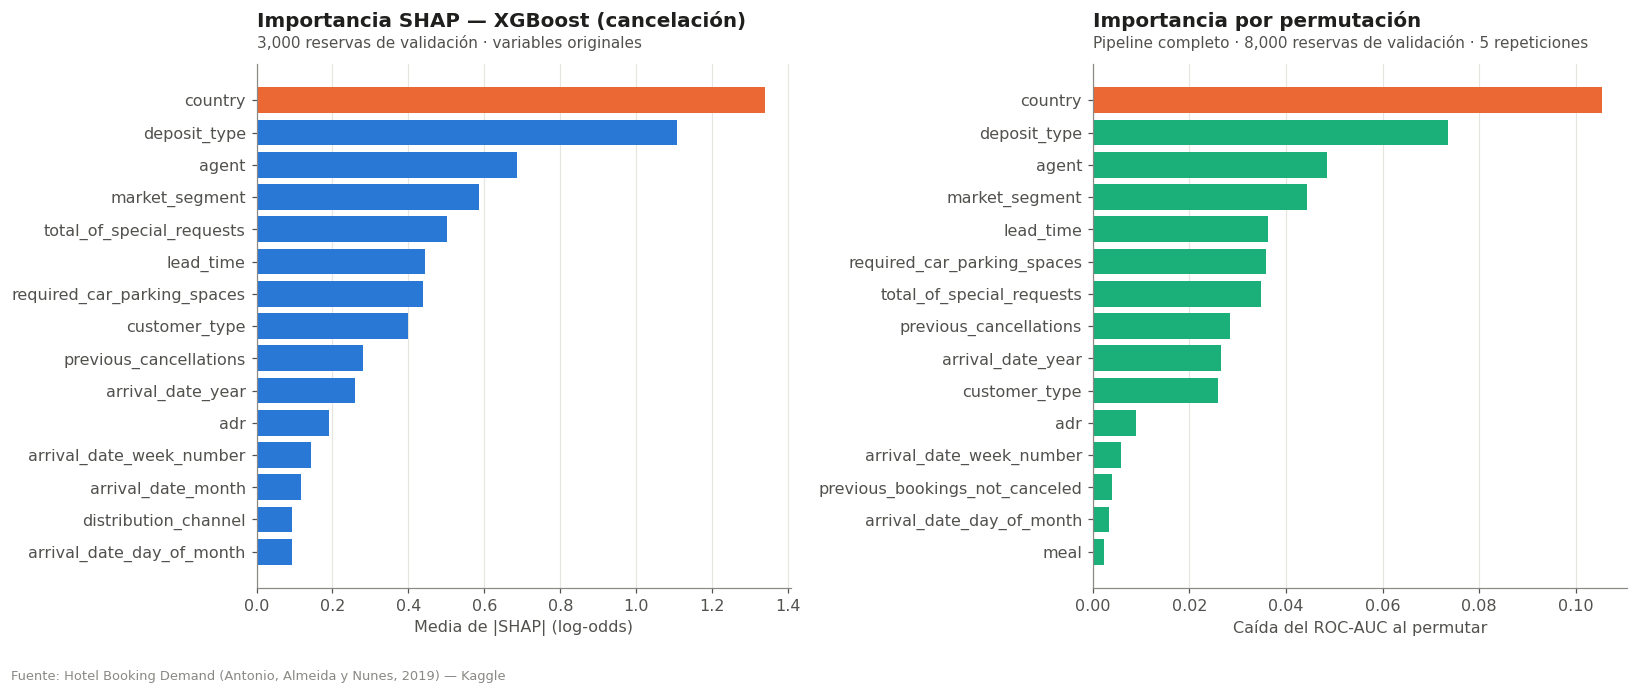

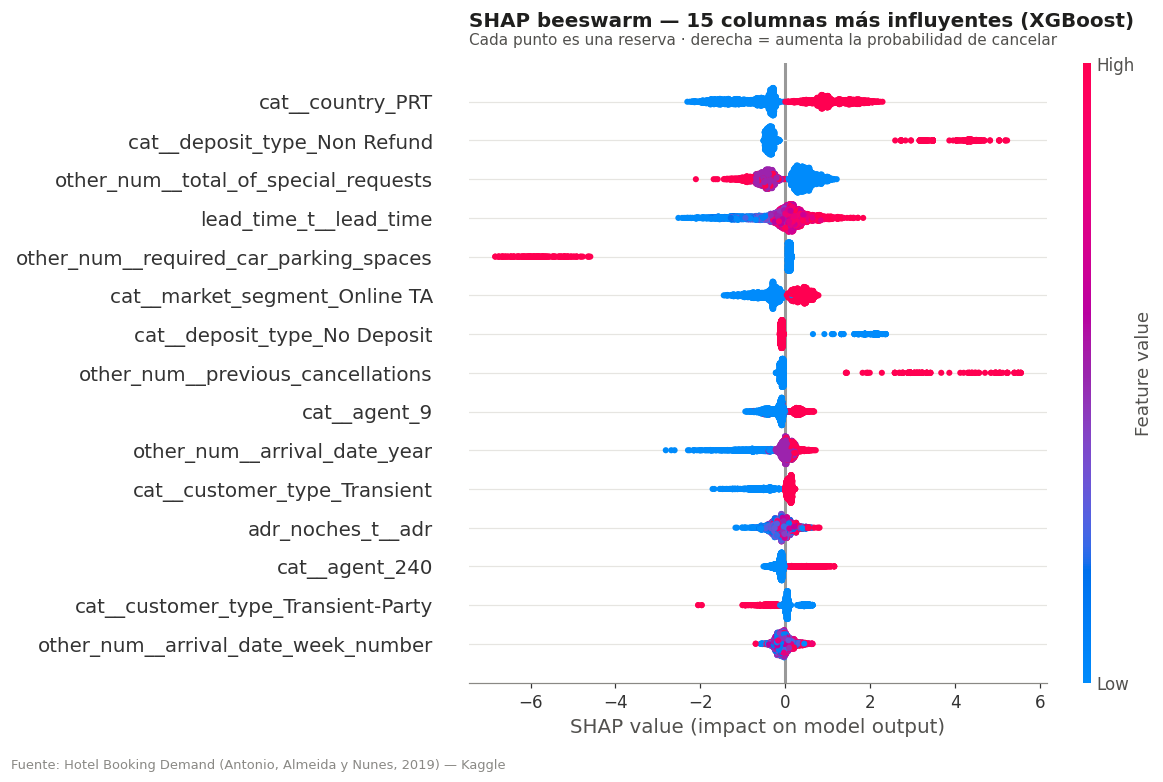

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = imp.head(15).iloc[::-1]
axes[0].barh(top.index, top["|SHAP| medio (XGB)"], color=[NARANJA if v == "country" else AZUL for v in top.index])
axes[0].grid(axis="x"); axes[0].grid(axis="y", visible=False); axes[0].set_xlabel("Media de |SHAP| (log-odds)")
titular(axes[0], "Importancia SHAP — XGBoost (cancelación)", "3,000 reservas de validación · variables originales")
topp = perm_c.head(15).iloc[::-1]
axes[1].barh(topp.index, topp.values, color=[NARANJA if v == "country" else AQUA for v in topp.index])
axes[1].grid(axis="x"); axes[1].grid(axis="y", visible=False); axes[1].set_xlabel("Caída del ROC-AUC al permutar")
titular(axes[1], "Importancia por permutación", "Pipeline completo · 8,000 reservas de validación · 5 repeticiones")
citar_fuente(fig, y=-0.04); plt.tight_layout(); guardar(fig, "7_1_importancia_clasificacion"); plt.show()

if SHAP_OK:
    top_cols = pd.Series(np.abs(sv_c).mean(0), index=FEATS_C).sort_values(ascending=False).head(15).index
    pos = [FEATS_C.index(c) for c in top_cols]
    plt.figure()
    shap.summary_plot(sv_c[:, pos], Xs_c[top_cols], show=False, max_display=15, plot_size=(11, 6.5))
    fig = plt.gcf(); ax = fig.axes[0]
    titular(ax, "SHAP beeswarm — 15 columnas más influyentes (XGBoost)",
            "Cada punto es una reserva · derecha = aumenta la probabilidad de cancelar")
    citar_fuente(fig, y=-0.02); guardar(fig, "7_1_shap_beeswarm"); plt.show()

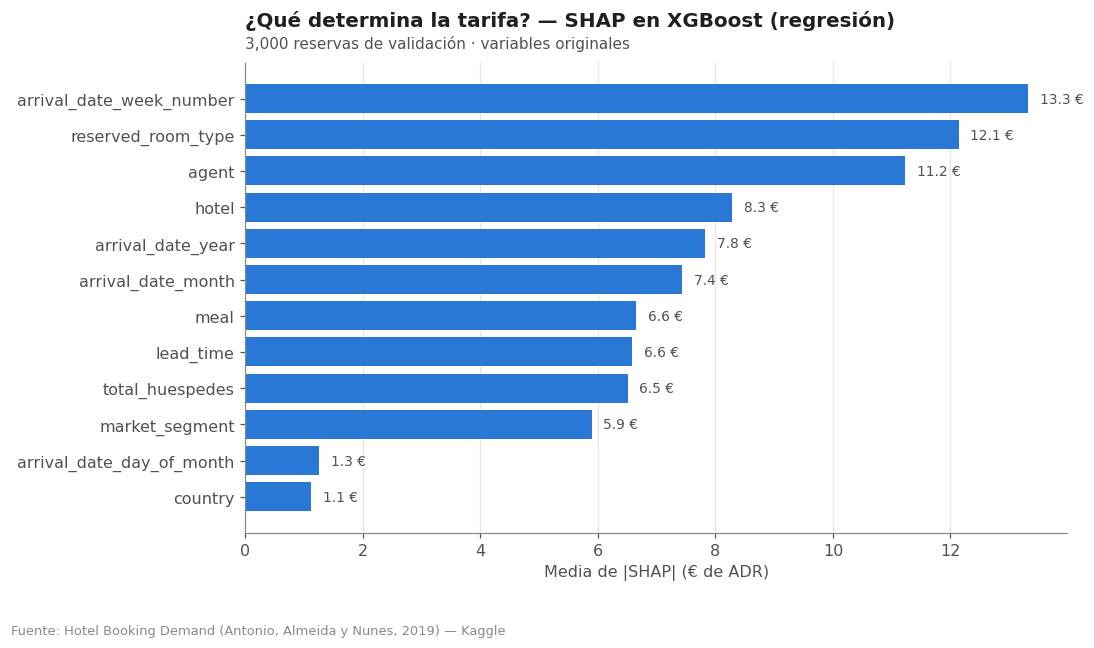

Top 8 variables por |SHAP| medio (€): {'arrival_date_week_number': 13.319999694824219, 'reserved_room_type': 12.140000343322754, 'agent': 11.229999542236328, 'hotel': 8.289999961853027, 'arrival_date_year': 7.829999923706055, 'arrival_date_month': 7.429999828338623, 'meal': 6.650000095367432, 'lead_time': 6.590000152587891}


In [ ]:
# --- SHAP para el modelo de regresión (XGBoost) ---
idx_shap_r = rng.choice(len(X_val_r), size=3_000, replace=False)
Xs_r = X_val_r.iloc[idx_shap_r]
sv_r = (shap.TreeExplainer(modelos_r["XGBoost"]).shap_values(Xs_r) if SHAP_OK else
        modelos_r["XGBoost"].get_booster().predict(xgboost.DMatrix(Xs_r), pred_contribs=True)[:, :-1])
shap_r = pd.DataFrame(np.abs(sv_r), columns=FEATS_R).T.groupby(ORIG_R).sum().T.mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
t = shap_r.head(12).iloc[::-1]
ax.barh(t.index, t.values, color=AZUL); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for i, v in enumerate(t.values):
    ax.text(v + 0.2, i, f"{v:.1f} €", va="center", fontsize=9, color=TINTA_2)
ax.set_xlabel("Media de |SHAP| (€ de ADR)")
titular(ax, "¿Qué determina la tarifa? — SHAP en XGBoost (regresión)", "3,000 reservas de validación · variables originales")
citar_fuente(fig, y=-0.06); plt.tight_layout(); guardar(fig, "7_2_shap_regresion"); plt.show()
print("Top 8 variables por |SHAP| medio (€):", shap_r.head(8).round(2).to_dict())

### 7.1 Auditoría de `country` y de `days_in_waiting_list` (compromiso de la Fase 2)
En la Fase 2, `country` fue la variable con mayor efecto en la ablación lineal (−0.041 de AUC) y se marcó como **riesgo de fuga**, porque el país puede completarse o corregirse al hacer el check-in (las reservas canceladas tienden a quedarse con el país por defecto). Se reentrena XGBoost **con los mismos hiperparámetros** quitando cada variable auditada.

In [ ]:
def auc_sin(variables_fuera):
    vars_ = [v for v in vars_clasif if v not in variables_fuera]
    num = [v for v in vars_ if v not in CAT_VARS]; cat = [v for v in vars_ if v in CAT_VARS]
    pipe = Pipeline([("pre", crear_preprocesador(num, cat)),
                     ("model", XGBClassifier(**modelos_c["XGBoost"].get_params()) .set_params(n_jobs=N_JOBS))])
    pipe.fit(df_train[vars_], y_train_c)
    p = pipe.predict_proba(df_val[vars_])[:, 1]
    return roc_auc_score(y_val_c, p), f1_score(y_val_c, (p >= umbral_optimo_f1(y_val_c, p)[0]).astype(int)), pipe

auc_ref = res_c_val["XGBoost"]["ROC-AUC"]
filas_abl = [{"Escenario": "XGBoost completo", "ROC-AUC val": auc_ref,
              "F1 val (umbral óptimo)": f1_score(y_val_c, (prob_val_c["XGBoost"] >= UMBRALES["XGBoost"]).astype(int))}]
pipes_abl = {}
for fuera in (["country"], ["days_in_waiting_list"], ["country", "days_in_waiting_list"]):
    a, f, pipes_abl[" + ".join(fuera)] = auc_sin(fuera)
    filas_abl.append({"Escenario": "− " + " − ".join(fuera), "ROC-AUC val": a, "F1 val (umbral óptimo)": f})
abl = pd.DataFrame(filas_abl).set_index("Escenario")
abl["Δ AUC vs. completo"] = abl["ROC-AUC val"] - auc_ref
display(abl.style.format("{:+.4f}", subset=["Δ AUC vs. completo"]).format("{:.4f}", subset=["ROC-AUC val", "F1 val (umbral óptimo)"]))

# ¿Cómo se relaciona country con la cancelación? (solo entrenamiento)
top_paises = df_train["country"].value_counts().head(8).index
tab_pais = (df_train[df_train["country"].isin(top_paises)].groupby("country")
            .agg(reservas=("is_canceled", "size"), cancelacion=("is_canceled", "mean"))
            .sort_values("reservas", ascending=False))
display(tab_pais.style.format({"reservas": "{:,}", "cancelacion": "{:.1%}"}).set_caption("Cancelación por país (train, 8 países principales)"))

,ROC-AUC val,F1 val (umbral óptimo),Δ AUC vs. completo
Escenario,,,
XGBoost completo,0.9485,0.8341,+0.0000
− country,0.9026,0.7740,-0.0459
− days_in_waiting_list,0.9476,0.8339,-0.0010
− country − days_in_waiting_list,0.9027,0.7722,-0.0458


,reservas,cancelacion
country,,
PRT,"34,158",57.4%
GBR,"8,434",20.3%
FRA,"7,321",18.1%
ESP,"5,977",26.3%
DEU,"5,135",16.3%
ITA,"2,583",35.7%
IRL,"2,365",24.4%
BEL,"1,652",21.0%


### 7.2 Interpretación
**¿Qué impulsa la cancelación?** Las tres técnicas coinciden en el *top* 7 (con cambios menores de orden):

1. **`country`** (1.º en SHAP y en permutación): ser de Portugal (`PRT`) es el factor individual más fuerte; las reservas portuguesas cancelan el **57.4 %**, frente a 16–26 % de Reino Unido, Francia, España o Alemania.
2. **`deposit_type`**: `Non Refund` empuja la predicción fuertemente hacia la cancelación (SHAP de +3 a +5 log-odds), coherente con el patrón de reservas grupales descrito en 6.4.
3. **`agent`** y **`market_segment`**: el canal *Online TA* y ciertas agencias (9, 240) elevan el riesgo.
4. **`total_of_special_requests`** y **`required_car_parking_spaces`**: son los factores **protectores**; pedir estacionamiento lleva el SHAP a −5/−7 (casi nadie que reserva estacionamiento cancela) y cada petición especial reduce el riesgo.
5. **`lead_time`** y **`previous_cancellations`**: más antelación y cancelaciones previas aumentan el riesgo.

**¿Qué determina la tarifa (regresión)?** La **semana de llegada** (13.3 € de efecto medio), el **tipo de habitación** (12.1 €), la **agencia** (11.2 €), el **hotel** (8.3 €), el **año** (7.8 €) y el **mes** (7.4 €), el **régimen de comidas** (6.7 €) y la **antelación** (6.6 €). Es decir: temporada, producto y canal, con una tendencia de precios al alza entre años.

**Auditoría de `country` (compromiso de la Fase 2).**

| Escenario | ROC-AUC val | F1 val | Δ AUC |
|---|---|---|---|
| XGBoost completo | 0.949 | 0.834 | — |
| − `country` | 0.903 | 0.774 | **−0.046** |
| − `days_in_waiting_list` | 0.948 | 0.834 | −0.001 |

* Quitar `country` cuesta 4.6 puntos de AUC, una dependencia similar a la observada con el modelo lineal en la Fase 2 (−0.041). El peso se concentra en una sola categoría (`PRT`), lo que refuerza la hipótesis de **fuga parcial**: en este dataset el país de muchas reservas se registra o corrige al hacer el check-in, así que las reservas que nunca llegan tienden a quedar con el valor por defecto del mercado local.
* **Decisión:** se mantiene `country` en el modelo principal porque es información que normalmente se captura al reservar y el rendimiento en prueba lo confirma, pero se documenta como **riesgo**: en producción debe verificarse que el país esté disponible al momento de la reserva. El modelo sin `country` (AUC 0.903) queda como **cota inferior conservadora**, y aun así iguala al baseline lineal completo.
* **`days_in_waiting_list`** no aporta señal ni al modelo lineal (Fase 2) ni a XGBoost (Δ = −0.001); es candidata a eliminarse en una versión simplificada del modelo para el dashboard.

## 8. Evaluación final en el conjunto de prueba

El conjunto de prueba se usa **por primera y única vez**. Todas las decisiones (hiperparámetros, arquitectura del MLP, umbrales, K) ya están congeladas con entrenamiento y validación. Los umbrales de clasificación son los elegidos en validación, **sin reajustar**.

In [ ]:
# --- Clasificación ---
prob_test_c = {"LogReg balanced (baseline)": base_lr.predict_proba(X_test_c)[:, 1],
               "Random Forest": modelos_c["Random Forest"].predict_proba(X_test_c)[:, 1],
               "XGBoost": modelos_c["XGBoost"].predict_proba(X_test_c)[:, 1],
               "MLP (PyTorch)": predecir_mlp(mlp, a_tensor(X_test_c))}
filas = []
for n, p in prob_test_c.items():
    m05 = metricas_clasif(y_test_c, p, 0.5); mu = metricas_clasif(y_test_c, p, UMBRALES[n])
    filas.append({"Modelo": n, "Umbral (de val)": UMBRALES[n], "Accuracy": mu["Accuracy"], "Precision": mu["Precision"],
                  "Recall": mu["Recall"], "F1": mu["F1"], "F1 @0.5": m05["F1"], "ROC-AUC": mu["ROC-AUC"],
                  "PR-AUC": mu["PR-AUC"], "ROC-AUC val": roc_auc_score(y_val_c, prob_val_c[n])})
final_c = pd.DataFrame(filas).set_index("Modelo")
final_c["Δ AUC (test − val)"] = final_c["ROC-AUC"] - final_c["ROC-AUC val"]
display(final_c.style.format("{:.3f}").highlight_max(subset=["F1", "ROC-AUC", "PR-AUC"], color="#d9ecff")
        .set_caption("Clasificación — PRUEBA (umbral fijado en validación)"))

# --- Regresión ---
filas = []
pred_test_r = {"Lineal simple (baseline)": base_simple.predict(df_test.loc[m_te, [VAR_SIMPLE]]),
               "OLS múltiple (referencia)": base_ols.predict(X_test_r)}
for n in ["Ridge", "Lasso", "ElasticNet", "Random Forest", "XGBoost"]:
    pred_test_r[n] = modelos_r[n].predict(X_test_r)
for n, p in pred_test_r.items():
    filas.append({"Modelo": n, **metricas_regres(y_test_r, p), "R2 val": res_r_val[n]["R2"]})
final_r = pd.DataFrame(filas).set_index("Modelo")
final_r["Δ R2 (test − val)"] = final_r["R2"] - final_r["R2 val"]
display(final_r.style.format("{:.3f}").highlight_min(subset=["MAE (€)", "RMSE (€)"], color="#d9ecff")
        .highlight_max(subset=["R2"], color="#d9ecff").set_caption("Regresión — PRUEBA (solo reservas con adr > 0)"))

cm_test = confusion_matrix(y_test_c, (prob_test_c[MEJOR_CLF] >= UMBRALES[MEJOR_CLF]).astype(int))
tn, fp, fn, tp = cm_test.ravel()
print(f"{MEJOR_CLF} en prueba: detecta {tp:,} de {tp + fn:,} cancelaciones ({tp / (tp + fn):.1%}); "
      f"{fp:,} falsas alarmas sobre {tn + fp:,} reservas que no cancelan ({fp / (tn + fp):.1%}).")

,Umbral (de val),Accuracy,Precision,Recall,F1,F1 @0.5,ROC-AUC,PR-AUC,ROC-AUC val,Δ AUC (test − val)
Modelo,,,,,,,,,,
LogReg balanced (baseline),0.491,0.815,0.707,0.815,0.757,0.756,0.904,0.849,0.902,0.001
Random Forest,0.502,0.854,0.766,0.844,0.803,0.802,0.937,0.901,0.938,-0.001
XGBoost,0.568,0.862,0.794,0.824,0.809,0.809,0.941,0.906,0.949,-0.008
MLP (PyTorch),0.538,0.846,0.742,0.862,0.798,0.793,0.936,0.899,0.943,-0.008


,MAE (€),RMSE (€),R2,R2 val,Δ R2 (test − val)
Modelo,,,,,
Lineal simple (baseline),32.394,42.024,0.186,0.202,-0.016
OLS múltiple (referencia),20.230,28.119,0.635,0.632,0.003
Ridge,20.230,28.119,0.635,0.632,0.003
Lasso,20.237,28.118,0.635,0.632,0.003
ElasticNet,20.255,28.134,0.635,0.632,0.003
Random Forest,7.963,14.433,0.904,0.906,-0.002
XGBoost,7.748,13.333,0.918,0.920,-0.002


XGBoost en prueba: detecta 5,143 de 6,243 cancelaciones (82.4%); 1,332 falsas alarmas sobre 11,427 reservas que no cancelan (11.7%).


### 8.1 Test de estrés temporal: entrenar con 2015–2016 y evaluar en 2017
Simula el despliegue real: el modelo solo conoce el pasado. Se reajustan el preprocesador y los modelos (con los **mismos hiperparámetros**) sobre las reservas con llegada en 2015–2016 de los tres conjuntos y se evalúa en las de 2017. Las copias idénticas comparten año de llegada, por lo que ningún grupo de duplicados cruza la frontera temporal.

In [ ]:
df_all = pd.concat([df_train, df_val, df_test], ignore_index=True)
tr_t, te_t = df_all[df_all["arrival_date_year"] < 2017], df_all[df_all["arrival_date_year"] == 2017]
assert grupos_compartidos(tr_t, te_t) == 0

# Clasificación
pre_t = crear_preprocesador(num_clasif, cat_clasif).fit(tr_t[vars_clasif])
Xt_tr, Xt_te = pre_t.transform(tr_t[vars_clasif]), pre_t.transform(te_t[vars_clasif])
spw_t = float((tr_t["is_canceled"] == 0).sum() / (tr_t["is_canceled"] == 1).sum())
filas = []
for n, est in [("LogReg balanced (baseline)", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
               ("XGBoost", XGBClassifier(**modelos_c["XGBoost"].get_params()).set_params(scale_pos_weight=spw_t, n_jobs=N_JOBS))]:
    est.fit(Xt_tr, tr_t["is_canceled"])
    p = est.predict_proba(Xt_te)[:, 1]
    filas.append({"Modelo": n, **metricas_clasif(te_t["is_canceled"], p, UMBRALES[n]),
                  "ROC-AUC partición aleatoria (test)": final_c.loc[n, "ROC-AUC"]})
temporal_c = pd.DataFrame(filas).set_index("Modelo")
temporal_c["Δ AUC (temporal − aleatoria)"] = temporal_c["ROC-AUC"] - temporal_c["ROC-AUC partición aleatoria (test)"]
display(temporal_c.style.format("{:.3f}").set_caption("Clasificación — entrenar 2015–2016, evaluar 2017"))

# Regresión
mt_tr, mt_te = tr_t["apto_regresion"] == 1, te_t["apto_regresion"] == 1
pre_tr = crear_preprocesador(num_regres, cat_regres, es_regresion=True).fit(tr_t[vars_regresion])
xr_tr, xr_te = pre_tr.transform(tr_t.loc[mt_tr, vars_regresion]), pre_tr.transform(te_t.loc[mt_te, vars_regresion])
filas = []
for n, est in [("Lineal simple (baseline)", None), ("Ridge", Ridge(**modelos_r["Ridge"].get_params())),
               ("XGBoost", XGBRegressor(**modelos_r["XGBoost"].get_params()).set_params(n_jobs=N_JOBS))]:
    if est is None:
        est = LinearRegression().fit(tr_t.loc[mt_tr, [VAR_SIMPLE]], tr_t.loc[mt_tr, "adr"])
        p = est.predict(te_t.loc[mt_te, [VAR_SIMPLE]])
    else:
        p = est.fit(xr_tr, tr_t.loc[mt_tr, "adr"]).predict(xr_te)
    filas.append({"Modelo": n, **metricas_regres(te_t.loc[mt_te, "adr"], p),
                  "R2 partición aleatoria (test)": final_r.loc[n, "R2"]})
temporal_r = pd.DataFrame(filas).set_index("Modelo")
display(temporal_r.style.format("{:.3f}").set_caption("Regresión — entrenar 2015–2016, evaluar 2017"))
print(f"ADR medio: 2015–2016 = {tr_t.loc[mt_tr, 'adr'].mean():.1f} € | 2017 = {te_t.loc[mt_te, 'adr'].mean():.1f} €")

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,ROC-AUC partición aleatoria (test),Δ AUC (temporal − aleatoria)
Modelo,,,,,,,,
LogReg balanced (baseline),0.775,0.659,0.866,0.749,0.881,0.832,0.904,-0.022
XGBoost,0.796,0.801,0.628,0.704,0.881,0.837,0.941,-0.060


,MAE (€),RMSE (€),R2,R2 partición aleatoria (test)
Modelo,,,,
Lineal simple (baseline),35.273,48.200,0.110,0.186
Ridge,21.650,29.908,0.657,0.635
XGBoost,18.491,25.222,0.756,0.918


ADR medio: 2015–2016 = 97.0 € | 2017 = 116.0 €


### 8.2 Interpretación de la evaluación final
**Prueba (17,670 reservas, nunca vistas):**

| Modelo | ROC-AUC | PR-AUC | F1 | Recall | Precision | Δ AUC vs. val |
|---|---|---|---|---|---|---|
| LogReg balanced (baseline) | 0.904 | 0.849 | 0.757 | 0.815 | 0.707 | +0.001 |
| Random Forest | 0.937 | 0.901 | 0.803 | 0.844 | 0.766 | −0.001 |
| MLP (PyTorch) | 0.936 | 0.899 | 0.798 | 0.862 | 0.742 | −0.008 |
| **XGBoost** | **0.941** | **0.906** | **0.809** | 0.824 | **0.794** | −0.008 |

| Modelo (regresión) | MAE (€) | RMSE (€) | R² | Δ R² vs. val |
|---|---|---|---|---|
| Lineal simple (baseline) | 32.39 | 42.02 | 0.186 | −0.016 |
| Ridge / Lasso / ElasticNet | 20.23–20.26 | 28.12–28.13 | 0.635 | +0.003 |
| Random Forest | 7.96 | 14.43 | 0.904 | −0.002 |
| **XGBoost** | **7.75** | **13.33** | **0.918** | −0.002 |

* **Generalización confirmada.** Las métricas de prueba difieren de las de validación en menos de 0.01 de AUC y de R², por lo que la selección de modelos y umbrales no estaba sobreajustada a validación. XGBoost sigue siendo el mejor modelo en ambos problemas; Random Forest y el MLP quedan prácticamente empatados en AUC (0.937 y 0.936), con el orden invertido respecto a validación.
* **Clasificación.** XGBoost detecta **5,143 de 6,243 cancelaciones (82.4 %)** con 1,332 falsas alarmas (11.7 % de las reservas que no cancelan). Frente al baseline, por cada 1,000 reservas detecta 3 cancelaciones más y genera **44 falsas alarmas menos** (75 frente a 120): la precisión sube de 70.7 % a 79.4 %. El MLP tiene el mayor Recall (0.862), a costa de más falsas alarmas (106 por cada 1,000).
* **Regresión.** XGBoost estima el ADR con un error medio de **7.75 € por noche** (≈ 8 % del ADR medio), frente a 32 € del baseline.

**Test de estrés temporal (entrenar 2015–2016 → evaluar 2017).**

| Modelo | ROC-AUC 2017 | Δ vs. partición aleatoria | F1 | Recall |
|---|---|---|---|---|
| LogReg balanced | 0.881 | −0.022 | 0.749 | 0.866 |
| XGBoost | 0.881 | **−0.060** | 0.704 | 0.628 |

| Modelo | R² 2017 | R² partición aleatoria |
|---|---|---|
| Ridge | 0.657 | 0.635 |
| XGBoost | 0.756 | 0.918 |

Este es el hallazgo más importante para el despliegue:

* **Ambos problemas sufren *concept drift*.** En clasificación, XGBoost pierde 6 puntos de AUC y queda al nivel de la regresión logística; además, con el umbral fijado en validación su Recall cae a 62.8 %, porque la tasa de cancelación y el perfil de las reservas cambian en 2017 (Fase 2: 36.2 % → 38.7 %).
* **La causa principal es la extrapolación temporal.** El ADR medio sube de 97 € (2015–2016) a **116 €** (2017). Los árboles no pueden predecir valores fuera del rango que vieron en entrenamiento ni extrapolar la tendencia de `arrival_date_year`, mientras que Ridge sí extrapola la tendencia lineal del año y **mejora** en 2017 (R² 0.657). Lo mismo ocurre con las variables de calendario y país en clasificación: el modelo flexible aprende patrones muy específicos de 2015–2016.
* **Implicación para producción:** el modelo debe **reentrenarse periódicamente** (p. ej., cada trimestre con ventana móvil), el umbral debe **recalibrarse** con datos recientes y, para la regresión, conviene modelar el ADR relativo a la tendencia (p. ej., índice de precios por año) en lugar del valor absoluto. Esto se documentará como trabajo futuro en el informe final.

## 9. Síntesis comparativa e impacto de negocio

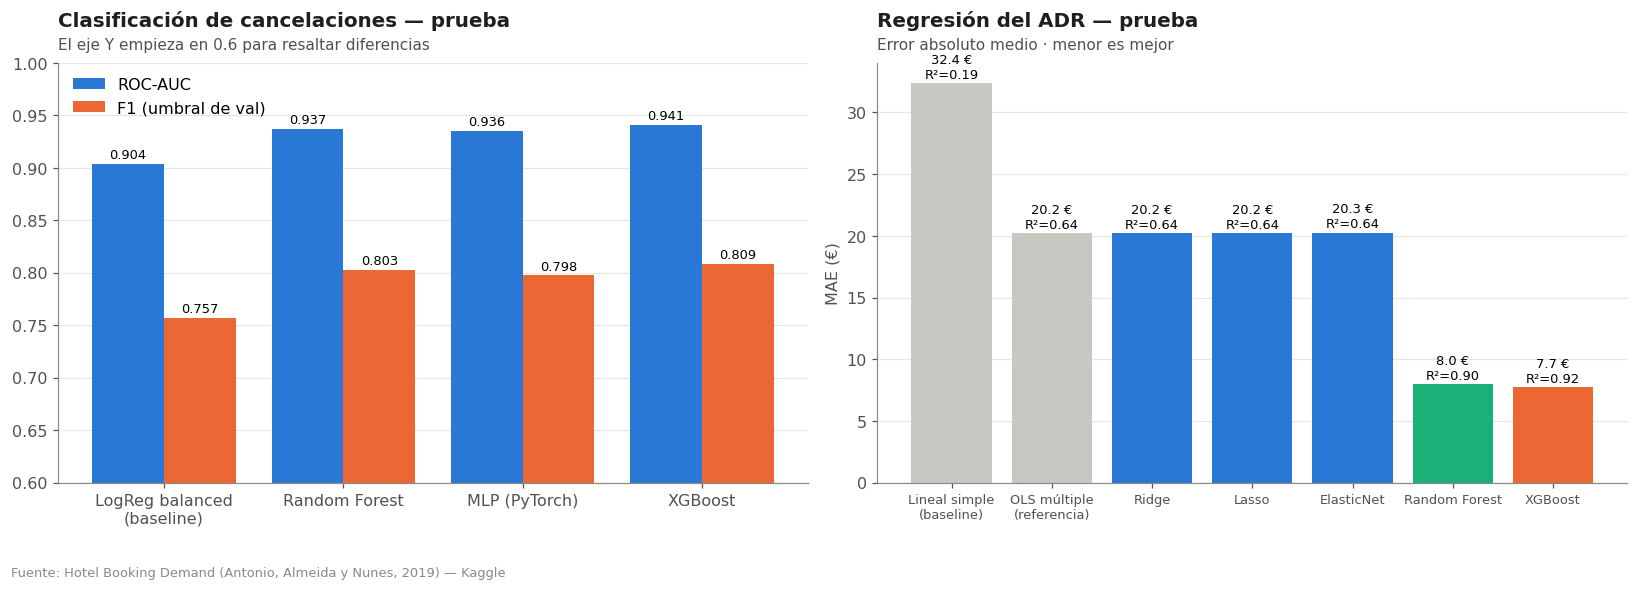

,"Cancelaciones detectadas / 1,000 reservas","Cancelaciones no detectadas / 1,000","Falsas alarmas / 1,000",Precision
Modelo,,,,
LogReg balanced (baseline),287.889078,65.421619,119.524618,70.7%
Random Forest,298.132428,55.178268,91.228070,76.6%
MLP (PyTorch),304.640634,48.670062,105.829089,74.2%
XGBoost,291.058291,62.252405,75.382003,79.4%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# Clasificación: F1 y ROC-AUC en prueba
orden = ["LogReg balanced (baseline)", "Random Forest", "MLP (PyTorch)", "XGBoost"]
x = np.arange(len(orden))
axes[0].bar(x - 0.2, final_c.loc[orden, "ROC-AUC"], 0.4, color=AZUL, label="ROC-AUC")
axes[0].bar(x + 0.2, final_c.loc[orden, "F1"], 0.4, color=NARANJA, label="F1 (umbral de val)")
for i, n in enumerate(orden):
    axes[0].text(i - 0.2, final_c.loc[n, "ROC-AUC"] + 0.005, f"{final_c.loc[n, 'ROC-AUC']:.3f}", ha="center", fontsize=8.5)
    axes[0].text(i + 0.2, final_c.loc[n, "F1"] + 0.005, f"{final_c.loc[n, 'F1']:.3f}", ha="center", fontsize=8.5)
axes[0].set_xticks(x); axes[0].set_xticklabels([o.replace(" (baseline)", "\n(baseline)") for o in orden])
axes[0].set_ylim(0.6, 1.0); axes[0].legend(loc="upper left")
titular(axes[0], "Clasificación de cancelaciones — prueba", "El eje Y empieza en 0.6 para resaltar diferencias")
# Regresión: MAE en prueba
orden_r2 = ["Lineal simple (baseline)", "OLS múltiple (referencia)", "Ridge", "Lasso", "ElasticNet", "Random Forest", "XGBoost"]
v = final_r.loc[orden_r2, "MAE (€)"]
axes[1].bar(range(len(v)), v, color=[GRIS_CLARO, GRIS_CLARO, AZUL, AZUL, AZUL, AQUA, NARANJA])
for i, val in enumerate(v):
    axes[1].text(i, val + 0.4, f"{val:.1f} €\nR²={final_r.loc[orden_r2[i], 'R2']:.2f}", ha="center", fontsize=8.5)
axes[1].set_xticks(range(len(v))); axes[1].set_xticklabels([o.replace(" (", "\n(") for o in orden_r2], fontsize=8.5)
axes[1].set_ylabel("MAE (€)")
titular(axes[1], "Regresión del ADR — prueba", "Error absoluto medio · menor es mejor")
citar_fuente(fig, y=-0.06); plt.tight_layout(); guardar(fig, "9_1_sintesis_prueba"); plt.show()

# Impacto de negocio: cancelaciones detectadas por cada 1,000 reservas en prueba
n_res = len(y_test_c)
imp_neg = []
for n in orden:
    cm = confusion_matrix(y_test_c, (prob_test_c[n] >= UMBRALES[n]).astype(int)); tn_, fp_, fn_, tp_ = cm.ravel()
    imp_neg.append({"Modelo": n, "Cancelaciones detectadas / 1,000 reservas": tp_ / n_res * 1000,
                    "Cancelaciones no detectadas / 1,000": fn_ / n_res * 1000,
                    "Falsas alarmas / 1,000": fp_ / n_res * 1000, "Precision": tp_ / (tp_ + fp_)})
display(pd.DataFrame(imp_neg).set_index("Modelo").style.format("{:.1f}").format({"Precision": "{:.1%}"}))

### 9.1 Síntesis

| Bloque | Mejor modelo | Métrica principal (prueba) | Mejora frente al baseline |
|---|---|---|---|
| Regresión del ADR | XGBoost | R² = 0.918 · MAE = 7.75 € | R² 0.186 → 0.918; MAE −76 % |
| Clasificación de la cancelación | XGBoost (umbral 0.568) | ROC-AUC = 0.941 · F1 = 0.809 | AUC +0.037; F1 +0.052; precisión +8.8 pp |
| Red neuronal | MLP 256-128-64 | ROC-AUC = 0.936 · F1 = 0.798 | AUC +0.032 |
| Segmentación | K-Means (K = 6) | Silueta = 0.22 (estable en prueba) | 6 perfiles con cancelación de 12 % a 53 % |

**Impacto de negocio (por cada 1,000 reservas):** el modelo XGBoost identifica **291 cancelaciones** de las 353 que ocurren y emite 75 falsas alarmas. Con el baseline, el hotel tendría 120 falsas alarmas para detectar 288. Si el hotel aplica *overbooking* o solicita confirmación solo a las reservas marcadas, la mayor precisión reduce el riesgo de "reubicar" huéspedes que sí llegan, que es el costo más alto de una mala predicción.

## 10. Persistencia de modelos y reproducibilidad

Se guardan los artefactos que necesitará el **dashboard de la Fase 4**:

| Archivo | Contenido |
|---|---|
| `transformadores.py` | `Winsorizer` y constructores de preprocesadores (necesario para cargar los *pipelines*) |
| `modelos_fase3/pipeline_clasificacion.joblib` | Preprocesador + mejor clasificador (entrada: variables originales) |
| `modelos_fase3/pipeline_regresion.joblib` | Preprocesador + mejor regresor del ADR |
| `modelos_fase3/pipeline_clustering.joblib` | Preprocesador + K-Means + PCA + mapa de etiquetas |
| `modelos_fase3/mlp_cancelacion.pt` | Pesos del MLP + configuración |
| `modelos_fase3/metadatos_fase3.json` | Variables de entrada, umbrales, métricas de prueba y perfiles de clúster |
| `requirements_fase3.txt` | Versiones exactas de las librerías |

In [ ]:
# 1. Pipelines de predicción (reciben las variables ORIGINALES, como en el simulador del dashboard)
pipe_clf = Pipeline([("pre", preproc_clasif), ("model", modelos_c[MEJOR_CLF])])
pipe_reg = Pipeline([("pre", preproc_regres), ("model", modelos_r[MEJOR_REG])])
joblib.dump(pipe_clf, os.path.join(DIR_MODELOS, "pipeline_clasificacion.joblib"), compress=3)
joblib.dump(pipe_reg, os.path.join(DIR_MODELOS, "pipeline_regresion.joblib"), compress=3)
joblib.dump({"preprocesador": prep_clust, "kmeans": kmeans, "pca": pca, "mapa_etiquetas": MAPA,
             "variables": VARS_CLUST}, os.path.join(DIR_MODELOS, "pipeline_clustering.joblib"), compress=3)
torch.save({"state_dict": mlp.state_dict(), "config": CONFIGS_MLP[MEJOR_MLP], "d_in": Xtr_t.shape[1],
            "columnas": FEATS_C}, os.path.join(DIR_MODELOS, "mlp_cancelacion.pt"))

# Comprobación: los pipelines guardados reproducen las predicciones
pc = joblib.load(os.path.join(DIR_MODELOS, "pipeline_clasificacion.joblib"))
assert np.allclose(pc.predict_proba(df_test[vars_clasif])[:, 1], prob_test_c[MEJOR_CLF])
pr = joblib.load(os.path.join(DIR_MODELOS, "pipeline_regresion.joblib"))
assert np.allclose(pr.predict(df_test.loc[m_te, vars_regresion]), pred_test_r[MEJOR_REG])

# 2. Metadatos y métricas
meta = {
    "fecha": time.strftime("%Y-%m-%d"), "seed": SEED,
    "clasificacion": {"modelo": MEJOR_CLF, "umbral": UMBRALES[MEJOR_CLF], "variables": vars_clasif,
                      "metricas_test": final_c.loc[MEJOR_CLF].to_dict()},
    "regresion": {"modelo": MEJOR_REG, "variables": vars_regresion, "metricas_test": final_r.loc[MEJOR_REG].to_dict()},
    "mlp": {"arquitectura": MEJOR_MLP, "umbral": UMBRALES["MLP (PyTorch)"],
            "metricas_test": final_c.loc["MLP (PyTorch)"].to_dict()},
    "clustering": {"k": K_OPT, "variables": VARS_CLUST,
                   "perfiles_train": json.loads(perfil_train.drop(columns="segmento_principal").to_json(orient="index"))},
}
with open(os.path.join(DIR_MODELOS, "metadatos_fase3.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2, default=float)
final_c.to_csv(os.path.join(DIR_MODELOS, "metricas_test_clasificacion.csv"))
final_r.to_csv(os.path.join(DIR_MODELOS, "metricas_test_regresion.csv"))
df_train.assign(cluster=cl_train)[["id_original", "cluster"]].to_csv(os.path.join(DIR_MODELOS, "clusters_train.csv"), index=False)

# 3. Dependencias
libs = ["pandas", "numpy", "scipy", "scikit-learn", "xgboost", "shap", "torch", "matplotlib", "joblib"]
with open("requirements_fase3.txt", "w") as f:
    f.write("\n".join(f"{l}=={version(l)}" for l in libs if SHAP_OK or l != "shap") + "\n")

print("Artefactos guardados en", DIR_MODELOS, ":", sorted(os.listdir(DIR_MODELOS)))
print("Figuras:", len(os.listdir(DIR_FIGURAS)), "archivos en", DIR_FIGURAS)
print(open("requirements_fase3.txt").read())

Artefactos guardados en modelos_fase3 : ['clusters_train.csv', 'metadatos_fase3.json', 'metricas_test_clasificacion.csv', 'metricas_test_regresion.csv', 'mlp_cancelacion.pt', 'pipeline_clasificacion.joblib', 'pipeline_clustering.joblib', 'pipeline_regresion.joblib']
Figuras: 17 archivos en figures_fase3
pandas==2.2.3
numpy==2.4.6
scipy==1.16.3
scikit-learn==1.6.1
xgboost==3.4.1
shap==0.54.1
torch==2.14.1+cu130
matplotlib==3.10.0
joblib==1.6.0



## 11. Conclusiones de la Fase 3
1. **Regresión.** Los modelos lineales regularizados (Ridge, Lasso, ElasticNet) alcanzan el techo de un modelo aditivo (R² ≈ 0.63) y la regularización óptima resulta mínima porque, con ~760 observaciones por parámetro, no hay varianza que controlar. Los ensambles capturan las interacciones de temporada, producto y canal y llevan el R² a **0.92** (XGBoost, MAE de 7.75 € en prueba).
2. **Clasificación.** Random Forest y XGBoost superan al baseline en todas las métricas; XGBoost es el mejor (ROC-AUC **0.941**, F1 **0.809** en prueba), con brechas train–val moderadas y métricas de prueba que confirman las de validación.
3. **MLP en PyTorch.** Tres arquitecturas con BatchNorm, Dropout, AdamW y parada temprana; la mejor (256-128-64) alcanza AUC 0.936 en prueba. Las curvas de pérdida muestran el punto de inicio del sobreajuste (≈ época 12), que la parada temprana controla. En datos tabulares no supera a XGBoost.
4. **Clustering.** El codo, la silueta y Davies-Bouldin coinciden en **K = 6**; el jerárquico de Ward confirma los segmentos extremos. Los perfiles son estables en prueba y tienen valor operativo: la cancelación va del 12 % (último minuto) al 53 % (anticipadas sin compromiso).
5. **Interpretabilidad.** SHAP, permutación e impureza coinciden: país, tipo de depósito, agencia/segmento, peticiones especiales, estacionamiento y antelación explican la cancelación; temporada, tipo de habitación, canal y año explican la tarifa. La auditoría confirma que `country` aporta ~0.05 de AUC y se mantiene como riesgo documentado; `days_in_waiting_list` no aporta señal.
6. **Robustez temporal.** El test 2015–2016 → 2017 revela *concept drift* (AUC −0.06; el ADR sube de 97 € a 116 €). Los modelos de árboles necesitan **reentrenamiento periódico y recalibración del umbral** en producción.

**Para la Fase 4** quedan listos los *pipelines* de predicción (entrada en variables originales), el modelo de segmentación con PCA y los metadatos (umbral, métricas, perfiles) en `modelos_fase3/`, junto con `transformadores.py` y `requirements_fase3.txt`.